# K-Means Student Clustering — 35 Kombinasi Feature Selection × Preprocessing

Notebook ini dibuat berdasarkan alur eksperimen K-Means project sebelumnya, tetapi dibuat
fleksibel untuk **5 feature selection case × 7 metode preprocessing = 35 kombinasi**.

## Feature selection

- `F12`: Course, Dosen, FD, PPT, LN, VBL, Submit, Ketepatan, avg_LO1, avg_LO2, avg_LO3, Total_LO
- `F11`: Course, Dosen, FD, PPT, LN, VBL, Submit, Ketepatan, avg_LO1, avg_LO2, avg_LO3
- `F9`: Course, Dosen, FD, PPT, LN, VBL, avg_LO1, avg_LO2, avg_LO3
- `F8`: Course, Dosen, FD, PPT, LN, VBL, Submit, Ketepatan
- `F6`: Course, Dosen, FD, PPT, LN, VBL

## Preprocessing

- `STANDARD`
- `MINMAX`
- `POWER`
- `QUANTILE`
- `ROBUST_MINMAX`
- `MINMAX_POWER`
- `STANDARD_L2`

Pengaturan utama cukup diubah pada satu cell:

```python
ACTIVE_CASE = "F8"
ACTIVE_TRANSFORM = "STANDARD"
```

Pemilihan K juga fleksibel:

```python
K_OVERRIDE = None   # otomatis
# K_OVERRIDE = 3    # manual
```

Selain menjalankan satu kombinasi secara detail, notebook menyediakan mode opsional untuk
menjalankan **seluruh 35 kombinasi** dan menghasilkan benchmark ringkas.

## Catatan metodologis penting

1. `Total_LO = avg_LO1 + avg_LO2 + avg_LO3`, sehingga `F12` mengandung redundansi linear.
2. `F11` dan `F9` sudah menggunakan komponen LO; `Total_LO` tidak boleh dianggap sebagai
   external validation yang independen.
3. `ROBUST_MINMAX` dipertahankan sesuai desain eksperimen, tetapi secara matematis
   RobustScaler diikuti MinMaxScaler dapat menghasilkan representasi yang sangat mirip
   bahkan ekuivalen dengan MinMaxScaler karena keduanya merupakan transformasi affine
   per-feature.
4. `STANDARD_L2` berbeda secara konsep: setelah StandardScaler, setiap **baris/record**
   dinormalisasi ke panjang L2 = 1. Ini mengubah geometri dari per-feature scaling menjadi
   per-record directional geometry.
5. `QUANTILE` menggunakan `output_distribution="normal"`.
6. `POWER` menggunakan Yeo-Johnson agar tetap dapat menangani nilai nol.


## 0. Import Library

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_samples,
    silhouette_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MinMaxScaler,
    Normalizer,
    PowerTransformer,
    QuantileTransformer,
    RobustScaler,
    StandardScaler,
)

warnings.filterwarnings("default", category=FutureWarning)

RANDOM_STATE = 42

print("Library berhasil di-import.")

Library berhasil di-import.


## 1. Konfigurasi Eksperimen

Cell ini adalah pusat kontrol notebook. Untuk menjalankan eksperimen yang berbeda, ubah
`ACTIVE_CASE` dan `ACTIVE_TRANSFORM` saja.

Untuk perbandingan 35 kombinasi yang fair, pertahankan kandidat K, random state, dan
parameter K-Means yang sama.


In [2]:
# ============================================================
# DATASET
# ============================================================

WINDOWS_DATA_PATH = Path(
    r"D:\Binus_Adhit_V1\Binus-Project\Folder-Clustering\Feature Engineering"
    r"\Hasil Feature Engineering\Dataset_Student_Clustering_V3.xlsx"
)

LOCAL_DATA_PATH = Path(
    "Dataset_Student_Clustering_V3.xlsx"
)

DATA_PATH = (
    WINDOWS_DATA_PATH
    if WINDOWS_DATA_PATH.exists()
    else LOCAL_DATA_PATH
)

SHEET_NAME = "Fitur_Clustering"


# ============================================================
# FEATURE CASES
# ============================================================

FEATURE_CASES = {
    "F12": [
        "Course_pct",
        "Dosen_pct",
        "FD_pct",
        "PPT_pct",
        "LN_pct",
        "VBL_pct",
        "Submit_pct",
        "Ketepatan_pct",
        "avg_LO1",
        "avg_LO2",
        "avg_LO3",
        "Total_LO",
    ],
    "F11": [
        "Course_pct",
        "Dosen_pct",
        "FD_pct",
        "PPT_pct",
        "LN_pct",
        "VBL_pct",
        "Submit_pct",
        "Ketepatan_pct",
        "avg_LO1",
        "avg_LO2",
        "avg_LO3",
    ],
    "F9": [
        "Course_pct",
        "Dosen_pct",
        "FD_pct",
        "PPT_pct",
        "LN_pct",
        "VBL_pct",
        "avg_LO1",
        "avg_LO2",
        "avg_LO3",
    ],
    "F8": [
        "Course_pct",
        "Dosen_pct",
        "FD_pct",
        "PPT_pct",
        "LN_pct",
        "VBL_pct",
        "Submit_pct",
        "Ketepatan_pct",
    ],
    "F6": [
        "Course_pct",
        "Dosen_pct",
        "FD_pct",
        "PPT_pct",
        "LN_pct",
        "VBL_pct",
    ],
}


# ============================================================
# PREPROCESSING METHODS
# ============================================================

TRANSFORM_METHODS = [
    "STANDARD",
    "MINMAX",
    "POWER",
    "ROBUST",       
    "QUANTILE",
    "ROBUST_MINMAX",
    "MINMAX_POWER",
    "STANDARD_L2",
]


# ============================================================
# ACTIVE EXPERIMENT
# ============================================================

# Ubah dua variabel ini untuk berpindah kombinasi.
ACTIVE_CASE = "F8"
ACTIVE_TRANSFORM = "ROBUST"


# ============================================================
# K SELECTION
# ============================================================

K_CANDIDATES = list(
    range(
        2,
        11,
    )
)

# None = otomatis.
# Integer = manual.
#
# Contoh:
# K_OVERRIDE = 3
K_OVERRIDE = 4

# Pilihan:
# "silhouette"
# "elbow"
# "combined"
AUTO_K_CRITERION = "combined"


# ============================================================
# K-MEANS
# ============================================================

SEARCH_N_INIT = 10
FINAL_N_INIT = 30
MAX_ITER = 500


# ============================================================
# QUANTILE TRANSFORMER
# ============================================================

QUANTILE_N_QUANTILES = 1000
QUANTILE_OUTPUT_DISTRIBUTION = "normal"


# ============================================================
# STABILITY
# ============================================================

SEED_STABILITY_RUNS = 10
GROUPED_NIM_RUNS = 10
GROUPED_NIM_FRACTION = 0.80


# ============================================================
# CLASS-LEVEL BUSINESS DIAGNOSTICS
# ============================================================

CLASS_GROUP_COLUMNS = [
    "Kode_Periode",
    "Kode Mata kuliah",
    "Kode Kelas",
]

CLASS_MEANINGFUL_SHARE = 0.10
MIN_CLASS_SIZE_FOR_BUSINESS = 20


# ============================================================
# OPTIONAL 35-COMBINATION BENCHMARK
# ============================================================

# False -> hanya kombinasi ACTIVE_CASE + ACTIVE_TRANSFORM.
# True  -> jalankan benchmark ringkas seluruh 35 kombinasi.
RUN_ALL_35_BENCHMARK = False

# None -> tiap kombinasi memilih K otomatis menggunakan AUTO_K_CRITERION.
# Integer -> seluruh 35 kombinasi dibandingkan pada K yang sama.
BENCHMARK_K_OVERRIDE = None


# ============================================================
# VALIDATE CONFIG
# ============================================================

if ACTIVE_CASE not in FEATURE_CASES:
    raise ValueError(
        f"ACTIVE_CASE harus salah satu dari "
        f"{list(FEATURE_CASES.keys())}"
    )

if ACTIVE_TRANSFORM not in TRANSFORM_METHODS:
    raise ValueError(
        f"ACTIVE_TRANSFORM harus salah satu dari "
        f"{TRANSFORM_METHODS}"
    )

if (
    K_OVERRIDE is not None
    and int(K_OVERRIDE) not in K_CANDIDATES
):
    raise ValueError(
        f"K_OVERRIDE harus berada pada "
        f"{K_CANDIDATES}"
    )

print(f"ACTIVE_CASE       : {ACTIVE_CASE}")
print(f"ACTIVE_TRANSFORM  : {ACTIVE_TRANSFORM}")
print(f"K_OVERRIDE        : {K_OVERRIDE}")
print(f"AUTO_K_CRITERION  : {AUTO_K_CRITERION}")

ACTIVE_CASE       : F8
ACTIVE_TRANSFORM  : ROBUST
K_OVERRIDE        : 4
AUTO_K_CRITERION  : combined


## 2. Load Data

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset V3 tidak ditemukan.\n"
        f"Windows path: {WINDOWS_DATA_PATH}\n"
        f"Local path  : {LOCAL_DATA_PATH.resolve()}\n\n"
        "Sesuaikan DATA_PATH atau letakkan dataset di folder notebook."
    )

df_raw = pd.read_excel(
    DATA_PATH,
    sheet_name=SHEET_NAME,
)

ID_COLUMNS = [
    "Kode_Periode",
    "Kode Kelas",
    "Kode Dosen",
    "Kode Mata kuliah",
    "Mata kuliah",
    "NIM",
]

ALL_MODEL_FEATURES = [
    "Course_pct",
    "Dosen_pct",
    "FD_pct",
    "PPT_pct",
    "LN_pct",
    "VBL_pct",
    "Submit_pct",
    "Ketepatan_pct",
    "avg_LO1",
    "avg_LO2",
    "avg_LO3",
    "Total_LO",
]

required_columns = (
    ID_COLUMNS
    + ALL_MODEL_FEATURES
)

missing_columns = sorted(
    set(required_columns)
    - set(df_raw.columns)
)

if missing_columns:
    raise ValueError(
        "Kolom dataset yang dibutuhkan tidak ditemukan: "
        f"{missing_columns}"
    )

print(f"Dataset          : {DATA_PATH.resolve()}")
print(f"Jumlah baris     : {len(df_raw):,}")
print(f"Jumlah kolom     : {df_raw.shape[1]}")
print(f"NIM unik         : {df_raw['NIM'].nunique():,}")
print(f"Kelas unik       : {df_raw['Kode Kelas'].nunique():,}")
print(
    f"Mata kuliah unik : "
    f"{df_raw['Kode Mata kuliah'].nunique():,}"
)

display(
    df_raw.head()
)

Dataset          : D:\Binus_Adhit_V1\Binus-Project\Folder-Clustering\Feature Engineering\Hasil Feature Engineering\Dataset_Student_Clustering_V3.xlsx
Jumlah baris     : 5,725
Jumlah kolom     : 18
NIM unik         : 583
Kelas unik       : 79
Mata kuliah unik : 33


,Kode_Periode,Kode Kelas,Kode Dosen,Kode Mata kuliah,Mata kuliah,NIM,Course_pct,Dosen_pct,FD_pct,PPT_pct,LN_pct,VBL_pct,Submit_pct,Ketepatan_pct,avg_LO1,avg_LO2,avg_LO3,Total_LO
0,2011,JFBA,D6248,ISYS6299,Information Systems Concept,124070401,70.833333,72.086667,70,60,80,90,100.000000,100.0,28.333333,37.777778,18.777778,84.888889
1,2011,JFBA,D6248,ISYS6299,Information Systems Concept,124071631,70.833333,72.086667,40,80,80,60,100.000000,100.0,31.666667,37.333333,17.444444,86.444444
2,2011,JFBA,D6248,ISYS6299,Information Systems Concept,124071822,70.833333,72.086667,90,70,60,90,100.000000,100.0,31.333333,38.555556,18.000000,87.888889
3,2011,JFBA,D6248,ISYS6299,Information Systems Concept,124077750,70.833333,72.086667,70,80,50,40,100.000000,100.0,30.222222,38.777778,20.000000,89.000000
4,2011,JFBA,D6248,ISYS6299,Information Systems Concept,124078311,70.833333,72.086667,40,70,70,60,66.666667,50.0,10.555556,23.333333,10.000000,43.888889


## 3. Definisi Feature Case Aktif

External profile dibentuk otomatis dari 12 fitur utama yang **tidak** digunakan pada
feature case aktif.

- `F8`: LO menjadi external profile.
- `F6`: Submit, Ketepatan, dan LO menjadi external profile.
- `F11` / `F9`: `Total_LO` tersisa, tetapi tidak independen dari LO1–LO3.
- `F12`: seluruh 12 fitur digunakan sehingga tidak ada numeric external profile.


In [4]:
df = df_raw.copy()

CLUSTER_FEATURES = (
    FEATURE_CASES[
        ACTIVE_CASE
    ]
    .copy()
)

EXTERNAL_PROFILE_FEATURES = [
    feature
    for feature in ALL_MODEL_FEATURES
    if feature not in CLUSTER_FEATURES
]

analysis_features = (
    CLUSTER_FEATURES
    + EXTERNAL_PROFILE_FEATURES
)

missing_summary = (
    df[
        analysis_features
    ]
    .isna()
    .sum()
)

display(
    missing_summary.to_frame(
        "Missing"
    )
)

if missing_summary.any():
    raise ValueError(
        "Masih terdapat missing value pada fitur analisis."
    )

for feature in analysis_features:
    if not pd.api.types.is_numeric_dtype(
        df[
            feature
        ]
    ):
        raise TypeError(
            f"Kolom {feature} harus numerik."
        )

X_raw = (
    df[
        CLUSTER_FEATURES
    ]
    .to_numpy(
        dtype=float
    )
)

if not np.isfinite(
    X_raw
).all():
    raise ValueError(
        "Feature space mengandung nilai non-finite."
    )

total_lo_recalculated = (
    df[
        [
            "avg_LO1",
            "avg_LO2",
            "avg_LO3",
        ]
    ]
    .sum(
        axis=1
    )
)

max_total_lo_diff = float(
    (
        df[
            "Total_LO"
        ]
        - total_lo_recalculated
    )
    .abs()
    .max()
)

print(
    f"Feature case aktif : "
    f"{ACTIVE_CASE}"
)
print(
    f"Jumlah fitur       : "
    f"{len(CLUSTER_FEATURES)}"
)

print(
    "\nCLUSTER_FEATURES:"
)

for feature in CLUSTER_FEATURES:
    print(
        f"- {feature}"
    )

print(
    "\nEXTERNAL_PROFILE_FEATURES:"
)

if EXTERNAL_PROFILE_FEATURES:
    for feature in EXTERNAL_PROFILE_FEATURES:
        print(
            f"- {feature}"
        )
else:
    print(
        "- Tidak ada."
    )

print(
    "\nMax |Total_LO - sum(avg_LO)|: "
    f"{max_total_lo_diff:.10f}"
)

if ACTIVE_CASE == "F12":
    print(
        "\nCATATAN F12: Total_LO redundant secara matematis "
        "dengan avg_LO1 + avg_LO2 + avg_LO3."
    )
elif ACTIVE_CASE in {
    "F11",
    "F9",
}:
    print(
        "\nCATATAN: Total_LO bukan external validation independen "
        "karena avg_LO1–avg_LO3 sudah digunakan dalam clustering."
    )
elif ACTIVE_CASE in {
    "F8",
    "F6",
}:
    print(
        "\nLO tidak digunakan dalam clustering dan dapat digunakan "
        "sebagai external profile/outcome."
    )

display(
    df[
        CLUSTER_FEATURES
    ]
    .describe()
    .round(
        3
    )
)

,Missing
Course_pct,0
Dosen_pct,0
FD_pct,0
PPT_pct,0
LN_pct,0
VBL_pct,0
Submit_pct,0
Ketepatan_pct,0
avg_LO1,0
avg_LO2,0


Feature case aktif : F8
Jumlah fitur       : 8

CLUSTER_FEATURES:
- Course_pct
- Dosen_pct
- FD_pct
- PPT_pct
- LN_pct
- VBL_pct
- Submit_pct
- Ketepatan_pct

EXTERNAL_PROFILE_FEATURES:
- avg_LO1
- avg_LO2
- avg_LO3
- Total_LO

Max |Total_LO - sum(avg_LO)|: 0.0000000000

LO tidak digunakan dalam clustering dan dapat digunakan sebagai external profile/outcome.


,Course_pct,Dosen_pct,FD_pct,PPT_pct,LN_pct,VBL_pct,Submit_pct,Ketepatan_pct
count,5725.000,5725.000,5725.000,5725.000,5725.000,5725.000,5725.000,5725.000
mean,76.812,77.405,66.183,70.190,70.063,66.335,95.700,88.667
std,4.987,4.943,17.339,14.209,14.480,17.306,12.182,16.724
min,58.519,60.667,0.000,20.000,20.000,0.000,0.000,0.000
25%,73.399,74.359,50.000,60.000,60.000,60.000,100.000,83.333
50%,77.143,78.095,70.000,70.000,70.000,70.000,100.000,100.000
75%,80.198,80.647,80.000,80.000,80.000,80.000,100.000,100.000
max,90.909,90.278,100.000,100.000,100.000,100.000,100.000,100.000


## 4. Eksplorasi Distribusi Fitur

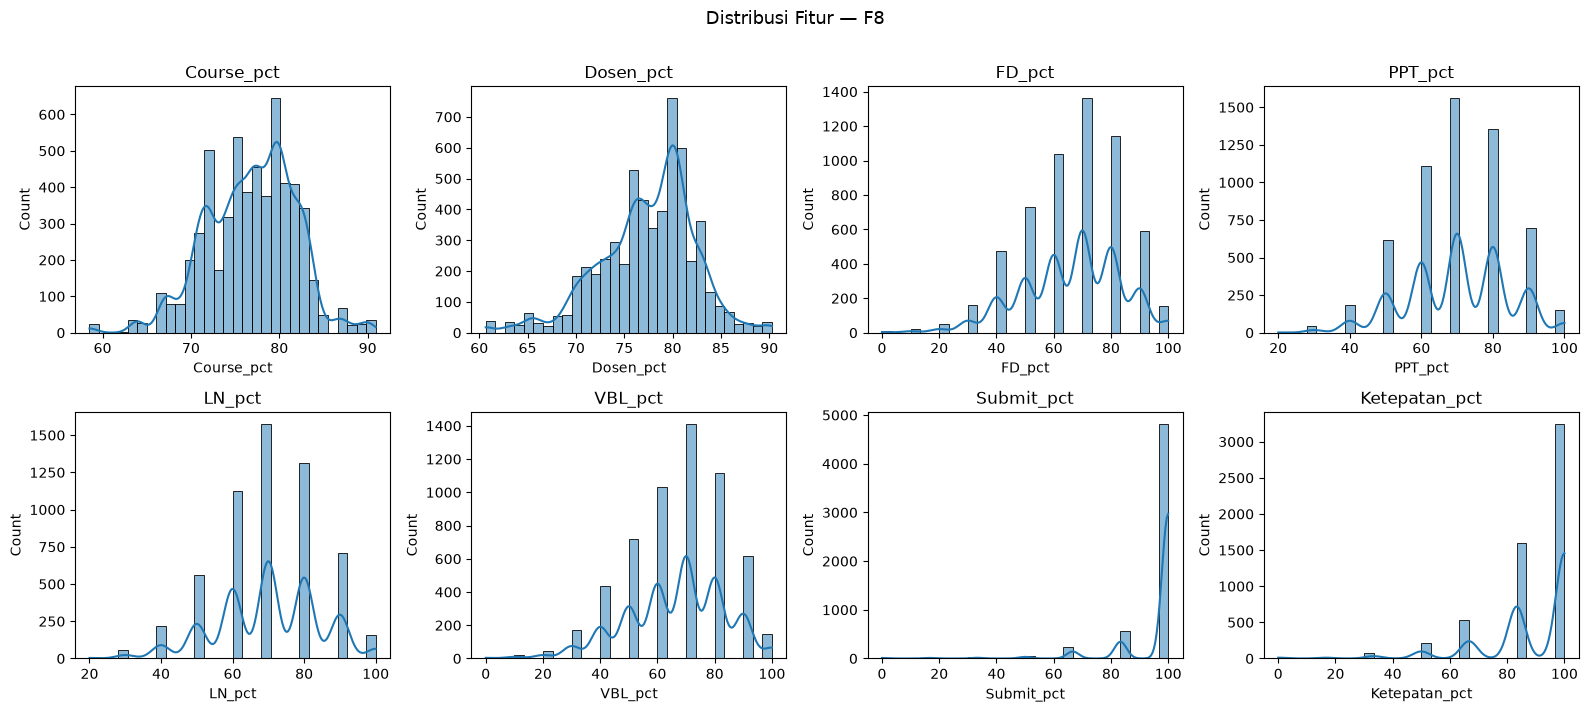

In [5]:
ncols = 4

nrows = int(
    np.ceil(
        len(
            CLUSTER_FEATURES
        )
        / ncols
    )
)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(
        16,
        nrows * 3.5,
    ),
)

axes_flat = np.asarray(
    axes
).reshape(
    -1
)

for ax, feature in zip(
    axes_flat,
    CLUSTER_FEATURES,
):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        kde=True,
        ax=ax,
    )

    ax.set_title(
        feature
    )

for ax in axes_flat[
    len(
        CLUSTER_FEATURES
    ):
]:
    ax.set_visible(
        False
    )

plt.suptitle(
    f"Distribusi Fitur — {ACTIVE_CASE}",
    fontsize=13,
    y=1.01,
)

plt.tight_layout()
plt.show()

## 5. Preprocessing

Definisi pipeline:

| Kode | Pipeline |
|---|---|
| `STANDARD` | StandardScaler |
| `MINMAX` | MinMaxScaler |
| `POWER` | PowerTransformer(Yeo-Johnson, standardize=True) |
| `QUANTILE` | QuantileTransformer(output_distribution='normal') |
| `ROBUST_MINMAX` | RobustScaler → MinMaxScaler |
| `MINMAX_POWER` | MinMaxScaler → PowerTransformer(Yeo-Johnson, standardize=True) |
| `STANDARD_L2` | StandardScaler → L2 Normalizer |

Notebook juga mencetak diagnostic raw IQR dan range sesudah preprocessing. Hal ini penting
untuk mendeteksi kasus seperti fitur dengan IQR=0.


In [6]:
def build_preprocessor(
    method_name,
    n_samples,
):
    method_name = (
        method_name
        .strip()
        .upper()
    )

    if method_name == "STANDARD":
        return StandardScaler()

    if method_name == "MINMAX":
        return MinMaxScaler()

    if method_name == "ROBUST":
        return RobustScaler()

    if method_name == "POWER":
        return PowerTransformer(
            method="yeo-johnson",
            standardize=True,
        )

    if method_name == "QUANTILE":
        return QuantileTransformer(
            n_quantiles=min(
                QUANTILE_N_QUANTILES,
                int(
                    n_samples
                ),
            ),
            output_distribution=(
                QUANTILE_OUTPUT_DISTRIBUTION
            ),
            random_state=RANDOM_STATE,
        )

    if method_name == "ROBUST_MINMAX":
        return Pipeline(
            steps=[
                (
                    "robust",
                    RobustScaler(),
                ),
                (
                    "minmax",
                    MinMaxScaler(),
                ),
            ]
        )

    if method_name == "MINMAX_POWER":
        return Pipeline(
            steps=[
                (
                    "minmax",
                    MinMaxScaler(),
                ),
                (
                    "power",
                    PowerTransformer(
                        method="yeo-johnson",
                        standardize=True,
                    ),
                ),
            ]
        )

    if method_name == "STANDARD_L2":
        return Pipeline(
            steps=[
                (
                    "standard",
                    StandardScaler(),
                ),
                (
                    "l2",
                    Normalizer(
                        norm="l2"
                    ),
                ),
            ]
        )

    raise ValueError(
        f"Preprocessing method tidak dikenal: "
        f"{method_name}"
    )


def preprocessing_diagnostics(
    raw_df,
    transformed_array,
    features,
):
    rows = []

    for feature_index, feature in enumerate(
        features
    ):
        raw_values = (
            raw_df[
                feature
            ]
            .to_numpy(
                dtype=float
            )
        )

        transformed_values = (
            transformed_array[
                :,
                feature_index,
            ]
        )

        q1 = np.quantile(
            raw_values,
            0.25,
        )

        median = np.quantile(
            raw_values,
            0.50,
        )

        q3 = np.quantile(
            raw_values,
            0.75,
        )

        rows.append(
            {
                "Feature": feature,
                "Raw_Min": (
                    np.min(
                        raw_values
                    )
                ),
                "Raw_Max": (
                    np.max(
                        raw_values
                    )
                ),
                "Raw_Mean": (
                    np.mean(
                        raw_values
                    )
                ),
                "Raw_Std": (
                    np.std(
                        raw_values,
                        ddof=1,
                    )
                ),
                "Q1": q1,
                "Median": median,
                "Q3": q3,
                "IQR": (
                    q3
                    - q1
                ),
                "Unique_Count": (
                    pd.Series(
                        raw_values
                    )
                    .nunique()
                ),
                "Transformed_Min": (
                    np.min(
                        transformed_values
                    )
                ),
                "Transformed_Max": (
                    np.max(
                        transformed_values
                    )
                ),
                "Transformed_Mean": (
                    np.mean(
                        transformed_values
                    )
                ),
                "Transformed_Std": (
                    np.std(
                        transformed_values,
                        ddof=1,
                    )
                ),
            }
        )

    return pd.DataFrame(
        rows
    )

## 6. Fit Preprocessing Aktif

In [7]:
preprocessor = build_preprocessor(
    ACTIVE_TRANSFORM,
    len(
        df
    ),
)

X_transformed = (
    preprocessor
    .fit_transform(
        X_raw
    )
)

if not np.isfinite(
    X_transformed
).all():
    raise ValueError(
        "Hasil preprocessing mengandung nilai non-finite."
    )

transformed_df = pd.DataFrame(
    X_transformed,
    columns=CLUSTER_FEATURES,
)

preprocess_diagnostic = (
    preprocessing_diagnostics(
        raw_df=df,
        transformed_array=X_transformed,
        features=CLUSTER_FEATURES,
    )
)

print(
    f"Preprocessing aktif: "
    f"{ACTIVE_TRANSFORM}"
)

display(
    preprocess_diagnostic.round(
        4
    )
)

zero_iqr_features = (
    preprocess_diagnostic.loc[
        np.isclose(
            preprocess_diagnostic[
                "IQR"
            ],
            0.0,
        ),
        "Feature",
    ]
    .tolist()
)

if zero_iqr_features:
    print(
        "\nWARNING — fitur dengan IQR=0:"
    )
    for feature in zero_iqr_features:
        print(
            f"- {feature}"
        )

    if ACTIVE_TRANSFORM in {
        "ROBUST_MINMAX",
    }:
        print(
            "\nROBUST_MINMAX tetap mengompresi output akhir ke [0,1], "
            "tetapi IQR=0 tetap perlu dicatat saat menginterpretasikan "
            "tahap RobustScaler."
        )

if ACTIVE_TRANSFORM == "ROBUST_MINMAX":
    print(
        "\nCATATAN: RobustScaler → MinMaxScaler dapat memberikan "
        "hasil yang identik/sangat mirip dengan MinMaxScaler saja "
        "karena keduanya affine per feature."
    )

if ACTIVE_TRANSFORM == "STANDARD_L2":
    row_norms = np.linalg.norm(
        X_transformed,
        axis=1,
    )

    print(
        "\nL2 norm per record setelah STANDARD_L2:"
    )
    print(
        f"min={row_norms.min():.6f}, "
        f"mean={row_norms.mean():.6f}, "
        f"max={row_norms.max():.6f}"
    )


Preprocessing aktif: ROBUST


,Feature,Raw_Min,Raw_Max,Raw_Mean,Raw_Std,Q1,Median,Q3,IQR,Unique_Count,Transformed_Min,Transformed_Max,Transformed_Mean,Transformed_Std
0,Course_pct,58.5185,90.9091,76.8119,4.9868,73.3987,77.1429,80.1980,6.7993,223,-2.7391,2.0246,-0.0487,0.7334
1,Dosen_pct,60.6667,90.2778,77.4053,4.9431,74.3590,78.0952,80.6467,6.2877,250,-2.7719,1.9375,-0.1097,0.7861
2,FD_pct,0.0000,100.0000,66.1834,17.3392,50.0000,70.0000,80.0000,30.0000,11,-2.3333,1.0000,-0.1272,0.5780
3,PPT_pct,20.0000,100.0000,70.1904,14.2093,60.0000,70.0000,80.0000,20.0000,9,-2.5000,1.5000,0.0095,0.7105
4,LN_pct,20.0000,100.0000,70.0629,14.4801,60.0000,70.0000,80.0000,20.0000,9,-2.5000,1.5000,0.0031,0.7240
5,VBL_pct,0.0000,100.0000,66.3354,17.3060,60.0000,70.0000,80.0000,20.0000,11,-3.5000,1.5000,-0.1832,0.8653
6,Submit_pct,0.0000,100.0000,95.7001,12.1819,100.0000,100.0000,100.0000,0.0000,7,-100.0000,0.0000,-4.2999,12.1819
7,Ketepatan_pct,0.0000,100.0000,88.6667,16.7245,83.3333,100.0000,100.0000,16.6667,7,-6.0000,0.0000,-0.6800,1.0035



WARNING — fitur dengan IQR=0:
- Submit_pct


## 7. Helper Functions — Evaluasi dan Pemilihan K

In [8]:
def find_elbow_k(
    k_values,
    inertia_values,
):
    x = np.asarray(
        k_values,
        dtype=float,
    )

    y = np.asarray(
        inertia_values,
        dtype=float,
    )

    x_norm = (
        x
        - x.min()
    ) / (
        x.max()
        - x.min()
    )

    y_norm = (
        y
        - y.min()
    ) / (
        y.max()
        - y.min()
    )

    p1 = np.array(
        [
            x_norm[0],
            y_norm[0],
        ]
    )

    p2 = np.array(
        [
            x_norm[-1],
            y_norm[-1],
        ]
    )

    line_vec = (
        p2
        - p1
    )

    line_vec_norm = (
        line_vec
        / np.linalg.norm(
            line_vec
        )
    )

    distances = []

    for xi, yi in zip(
        x_norm,
        y_norm,
    ):
        point_vec = (
            np.array(
                [
                    xi,
                    yi,
                ]
            )
            - p1
        )

        projection_length = np.dot(
            point_vec,
            line_vec_norm,
        )

        projection_point = (
            p1
            + projection_length
            * line_vec_norm
        )

        distance = np.linalg.norm(
            np.array(
                [
                    xi,
                    yi,
                ]
            )
            - projection_point
        )

        distances.append(
            distance
        )

    return int(
        x[
            np.argmax(
                distances
            )
        ]
    )


def cluster_size_metrics(
    labels,
):
    counts = (
        pd.Series(
            labels
        )
        .value_counts()
    )

    return {
        "Smallest_Cluster": int(
            counts.min()
        ),
        "Largest_Cluster": int(
            counts.max()
        ),
        "Largest_Cluster_Share": float(
            counts.max()
            / len(
                labels
            )
        ),
    }


def select_auto_k(
    evaluation_df,
    criterion,
):
    criterion = (
        criterion
        .strip()
        .lower()
    )

    if criterion == "silhouette":
        return int(
            evaluation_df.loc[
                evaluation_df[
                    "Silhouette"
                ].idxmax(),
                "K",
            ]
        )

    if criterion == "elbow":
        return find_elbow_k(
            evaluation_df[
                "K"
            ].to_numpy(),
            evaluation_df[
                "Inertia"
            ].to_numpy(),
        )

    if criterion == "combined":
        ranked = (
            evaluation_df
            .copy()
        )

        ranked[
            "Rank_Silhouette"
        ] = (
            ranked[
                "Silhouette"
            ]
            .rank(
                ascending=False,
                method="min",
            )
        )

        ranked[
            "Rank_DBI"
        ] = (
            ranked[
                "DBI"
            ]
            .rank(
                ascending=True,
                method="min",
            )
        )

        ranked[
            "Rank_CH"
        ] = (
            ranked[
                "CH"
            ]
            .rank(
                ascending=False,
                method="min",
            )
        )

        elbow_k = find_elbow_k(
            ranked[
                "K"
            ].to_numpy(),
            ranked[
                "Inertia"
            ].to_numpy(),
        )

        ranked[
            "Elbow_Distance"
        ] = (
            ranked[
                "K"
            ]
            - elbow_k
        ).abs()

        ranked[
            "Rank_Elbow"
        ] = (
            ranked[
                "Elbow_Distance"
            ]
            .rank(
                ascending=True,
                method="min",
            )
        )

        ranked[
            "Combined_Rank"
        ] = (
            ranked[
                [
                    "Rank_Silhouette",
                    "Rank_DBI",
                    "Rank_CH",
                    "Rank_Elbow",
                ]
            ]
            .mean(
                axis=1
            )
        )

        return int(
            ranked.loc[
                ranked[
                    "Combined_Rank"
                ].idxmin(),
                "K",
            ]
        )

    raise ValueError(
        "AUTO_K_CRITERION harus silhouette/elbow/combined."
    )


## 8. Elbow, Silhouette, DBI, dan CH — Search K

Seluruh kandidat K dievaluasi pada **ruang hasil preprocessing aktif**.


In [9]:
k_search_rows = []

for k in K_CANDIDATES:
    model_k = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=SEARCH_N_INIT,
        max_iter=MAX_ITER,
    )

    labels_k = (
        model_k
        .fit_predict(
            X_transformed
        )
    )

    size_info = (
        cluster_size_metrics(
            labels_k
        )
    )

    k_search_rows.append(
        {
            "K": k,
            "Inertia": (
                model_k.inertia_
            ),
            "Silhouette": (
                silhouette_score(
                    X_transformed,
                    labels_k,
                )
            ),
            "DBI": (
                davies_bouldin_score(
                    X_transformed,
                    labels_k,
                )
            ),
            "CH": (
                calinski_harabasz_score(
                    X_transformed,
                    labels_k,
                )
            ),
            **size_info,
        }
    )

k_evaluation = pd.DataFrame(
    k_search_rows
)

display(
    k_evaluation.round(
        5
    )
)

elbow_k = find_elbow_k(
    k_evaluation[
        "K"
    ],
    k_evaluation[
        "Inertia"
    ],
)

silhouette_best_k = int(
    k_evaluation.loc[
        k_evaluation[
            "Silhouette"
        ].idxmax(),
        "K",
    ]
)

print(
    f"Elbow K              : "
    f"{elbow_k}"
)

print(
    f"Best Silhouette K    : "
    f"{silhouette_best_k}"
)

print(
    f"Best Silhouette      : "
    f"{k_evaluation['Silhouette'].max():.5f}"
)


,K,Inertia,Silhouette,DBI,CH,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Share
0,2,283853.18498,0.84558,0.43852,11896.37685,346,5379,0.93956
1,3,104726.44369,0.84056,0.48420,21012.82863,113,4820,0.84192
2,4,42983.12658,0.84195,0.34072,36864.55867,60,4820,0.84192
3,5,26867.91560,0.84863,0.35295,45081.74489,36,4820,0.84192
4,6,22255.76898,0.85146,0.29772,43768.78560,24,4820,0.84192
5,7,18708.44365,0.29908,0.74131,43563.12232,24,2735,0.47773
6,8,16202.19801,0.30189,0.63700,43235.08094,17,2786,0.48664
7,9,15100.48497,0.24749,0.85990,40639.17554,17,1929,0.33694
8,10,14232.50366,0.24096,0.90665,38357.36371,17,1463,0.25555


Elbow K              : 4
Best Silhouette K    : 6
Best Silhouette      : 0.85146


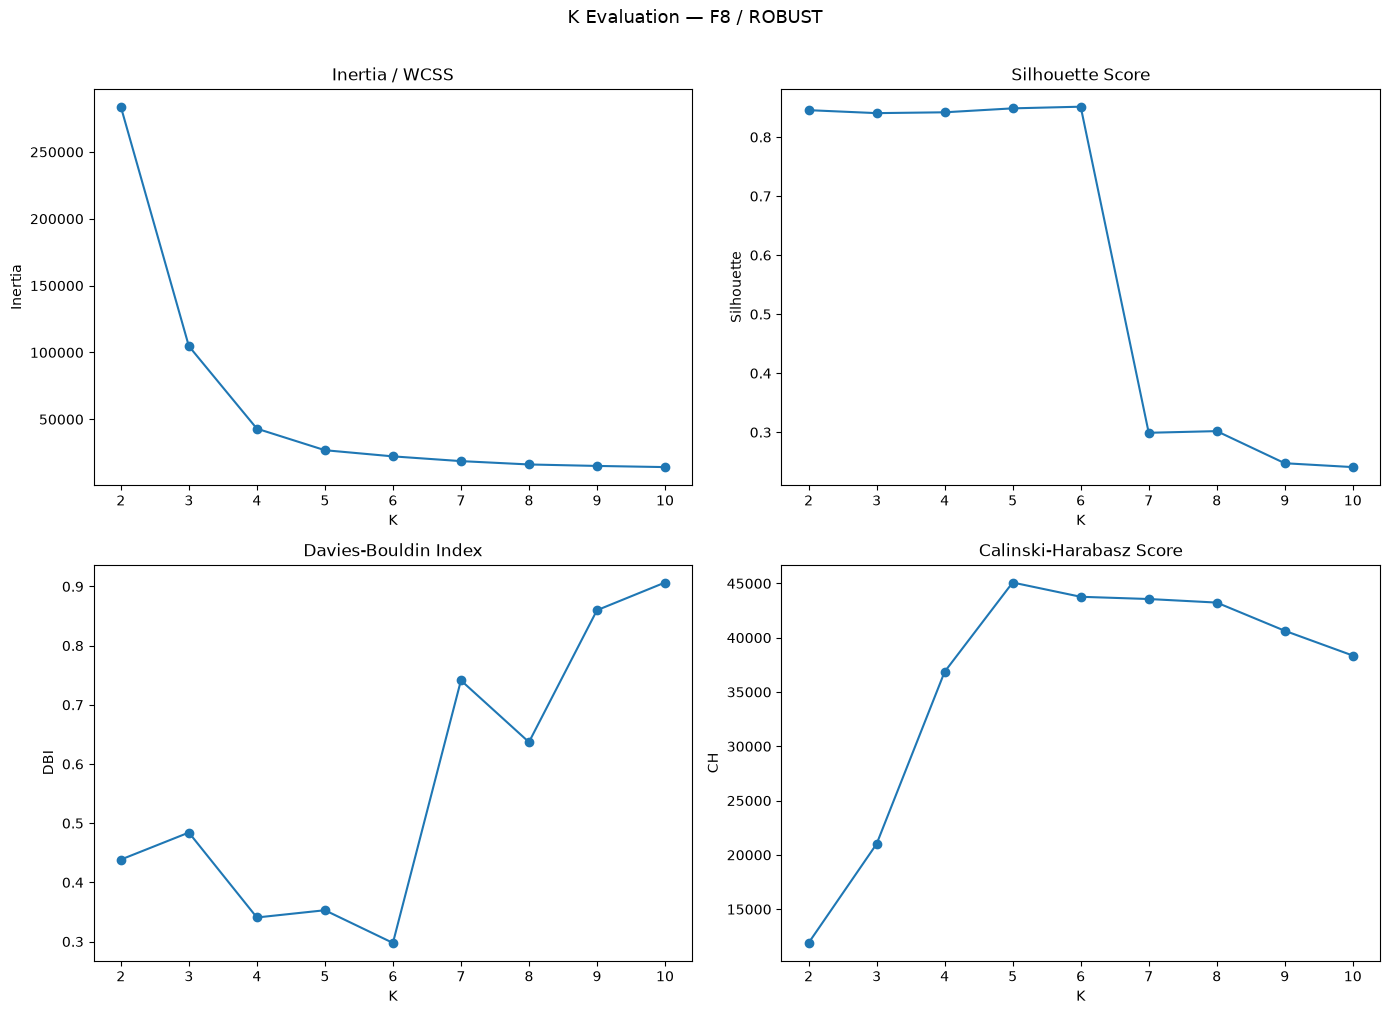

In [10]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        14,
        10,
    ),
)

plot_specs = [
    (
        "Inertia",
        "Inertia / WCSS",
    ),
    (
        "Silhouette",
        "Silhouette Score",
    ),
    (
        "DBI",
        "Davies-Bouldin Index",
    ),
    (
        "CH",
        "Calinski-Harabasz Score",
    ),
]

for ax, (
    metric,
    title,
) in zip(
    axes.flat,
    plot_specs,
):
    ax.plot(
        k_evaluation[
            "K"
        ],
        k_evaluation[
            metric
        ],
        marker="o",
    )

    ax.set_xlabel(
        "K"
    )

    ax.set_ylabel(
        metric
    )

    ax.set_title(
        title
    )

    ax.set_xticks(
        K_CANDIDATES
    )

plt.suptitle(
    f"K Evaluation — {ACTIVE_CASE} / {ACTIVE_TRANSFORM}",
    fontsize=13,
    y=1.01,
)

plt.tight_layout()
plt.show()


## 9. Pilih K Otomatis atau Manual

In [11]:
AUTO_K = select_auto_k(
    k_evaluation,
    AUTO_K_CRITERION,
)

if K_OVERRIDE is None:
    K_FINAL = AUTO_K
    K_SELECTION_MODE = (
        f"AUTO_{AUTO_K_CRITERION.upper()}"
    )
else:
    K_FINAL = int(
        K_OVERRIDE
    )
    K_SELECTION_MODE = (
        "MANUAL_OVERRIDE"
    )

print(
    f"AUTO_K             : "
    f"{AUTO_K}"
)

print(
    f"K_SELECTION_MODE   : "
    f"{K_SELECTION_MODE}"
)

print(
    f"K_FINAL            : "
    f"{K_FINAL}"
)

display(
    k_evaluation[
        k_evaluation[
            "K"
        ]
        == K_FINAL
    ]
    .round(
        5
    )
)


AUTO_K             : 5
K_SELECTION_MODE   : MANUAL_OVERRIDE
K_FINAL            : 4


,K,Inertia,Silhouette,DBI,CH,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Share
2,4,42983.12658,0.84195,0.34072,36864.55867,60,4820,0.84192


## 10. Fit K-Means Final

In [12]:
kmeans_final = KMeans(
    n_clusters=K_FINAL,
    random_state=RANDOM_STATE,
    n_init=FINAL_N_INIT,
    max_iter=MAX_ITER,
)

labels_final = (
    kmeans_final
    .fit_predict(
        X_transformed
    )
)

df[
    "Cluster"
] = (
    labels_final
    .astype(
        int
    )
)

cluster_distribution = (
    df[
        "Cluster"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "Cluster"
    )
    .to_frame(
        "Jumlah"
    )
)

cluster_distribution[
    "Persen"
] = (
    cluster_distribution[
        "Jumlah"
    ]
    / len(
        df
    )
    * 100
)

print(
    f"K-Means final dijalankan dengan "
    f"K={K_FINAL}"
)

display(
    cluster_distribution.round(
        2
    )
)


K-Means final dijalankan dengan K=4


,Jumlah,Persen
Cluster,,
0,4820,84.19
1,60,1.05
2,559,9.76
3,286,5.00


## Simpan Model K-Means dan Scaler ke `.pkl`

Cell berikut menyimpan **model K-Means final** dan **preprocessor/scaler yang sudah di-fit**.

File yang dihasilkan:

- `clustering_model.pkl`
- `scaler.pkl`

Keduanya disimpan di folder `output/` agar konsisten dengan file hasil notebook lainnya.


In [13]:
# ============================================================
# SIMPAN MODEL DAN SCALER
# ============================================================

import joblib

from IPython.display import FileLink, display


MODEL_OUTPUT_DIR = Path(
    "output"
)

MODEL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


MODEL_PATH = (
    MODEL_OUTPUT_DIR
    / "clustering_model.pkl"
)

SCALER_PATH = (
    MODEL_OUTPUT_DIR
    / "scaler.pkl"
)


# ============================================================
# VALIDASI SEBELUM DISIMPAN
# ============================================================

if not hasattr(
    kmeans_final,
    "cluster_centers_",
):
    raise RuntimeError(
        "kmeans_final belum di-fit. "
        "Jalankan cell Final K-Means terlebih dahulu."
    )


if not hasattr(
    preprocessor,
    "transform",
):
    raise RuntimeError(
        "preprocessor/scaler belum tersedia."
    )


# ============================================================
# SAVE
# ============================================================

joblib.dump(
    kmeans_final,
    MODEL_PATH,
)

joblib.dump(
    preprocessor,
    SCALER_PATH,
)


print(
    "Model dan scaler berhasil disimpan."
)

print(
    f"Model  : {MODEL_PATH.resolve()}"
)

print(
    f"Scaler : {SCALER_PATH.resolve()}"
)


# ============================================================
# LINK FILE
# ============================================================

print(
    "\nFile:"
)

display(
    FileLink(
        str(
            MODEL_PATH
        )
    )
)

display(
    FileLink(
        str(
            SCALER_PATH
        )
    )
)


Model dan scaler berhasil disimpan.
Model  : D:\Binus_Adhit_V1\Binus-Project\Folder-Clustering\Modeling\KMeans-Model\Robust-Scaler\output\clustering_model.pkl
Scaler : D:\Binus_Adhit_V1\Binus-Project\Folder-Clustering\Modeling\KMeans-Model\Robust-Scaler\output\scaler.pkl

File:


d:\Binus_Adhit_V1\Binus-Project\Folder-Clustering\Modeling\KMeans-Model\Robust-Scaler\output\clustering_model.pkl

d:\Binus_Adhit_V1\Binus-Project\Folder-Clustering\Modeling\KMeans-Model\Robust-Scaler\output\scaler.pkl

## 11. Evaluasi Internal Model Final

In [14]:
sil_score = silhouette_score(
    X_transformed,
    labels_final,
)

dbi_score = davies_bouldin_score(
    X_transformed,
    labels_final,
)

ch_score = calinski_harabasz_score(
    X_transformed,
    labels_final,
)

inertia = (
    kmeans_final.inertia_
)

size_final = cluster_size_metrics(
    labels_final
)

final_metrics = pd.DataFrame(
    [
        {
            "Feature_Case": ACTIVE_CASE,
            "N_Features": (
                len(
                    CLUSTER_FEATURES
                )
            ),
            "Transform": (
                ACTIVE_TRANSFORM
            ),
            "K": K_FINAL,
            "K_Selection_Mode": (
                K_SELECTION_MODE
            ),
            "Silhouette": (
                sil_score
            ),
            "DBI": (
                dbi_score
            ),
            "CH": (
                ch_score
            ),
            "Inertia": (
                inertia
            ),
            **size_final,
        }
    ]
)

display(
    final_metrics.round(
        5
    )
)


,Feature_Case,N_Features,Transform,K,K_Selection_Mode,Silhouette,DBI,CH,Inertia,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Share
0,F8,8,ROBUST,4,MANUAL_OVERRIDE,0.84195,0.34072,36864.55867,42983.12658,60,4820,0.84192


## 12. Profil Cluster pada Skala Asli

Empirical mean dan median dihitung langsung dari data asli. Ini selalu valid untuk seluruh
preprocessing, termasuk `STANDARD_L2` yang tidak mempunyai inverse transform unik.

Notebook juga mencoba mengembalikan mathematical K-Means centroid ke skala asli bila
pipeline preprocessing mendukung `inverse_transform`.


In [15]:
empirical_profile_mean = (
    df.groupby(
        "Cluster"
    )[
        CLUSTER_FEATURES
    ]
    .mean()
)

empirical_profile_median = (
    df.groupby(
        "Cluster"
    )[
        CLUSTER_FEATURES
    ]
    .median()
)

print(
    "Empirical cluster mean — skala asli:"
)

display(
    empirical_profile_mean.round(
        3
    )
)

print(
    "Empirical cluster median — skala asli:"
)

display(
    empirical_profile_median.round(
        3
    )
)

centers_transformed_df = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns=CLUSTER_FEATURES,
)

centers_transformed_df.index.name = (
    "Cluster"
)

try:
    centers_original_array = (
        preprocessor
        .inverse_transform(
            kmeans_final.cluster_centers_
        )
    )

    centroid_original_df = pd.DataFrame(
        centers_original_array,
        columns=CLUSTER_FEATURES,
    )

    centroid_original_df.index.name = (
        "Cluster"
    )

    print(
        "Mathematical centroid berhasil dikembalikan "
        "ke skala asli:"
    )

    display(
        centroid_original_df.round(
            3
        )
    )

except Exception as error:
    centroid_original_df = (
        pd.DataFrame()
    )

    print(
        "Centroid transformed tidak dapat di-inverse secara unik."
    )

    print(
        "Gunakan empirical_profile_mean sebagai profil utama."
    )

    print(
        f"Reason: {type(error).__name__}: {error}"
    )


Empirical cluster mean — skala asli:


,Course_pct,Dosen_pct,FD_pct,PPT_pct,LN_pct,VBL_pct,Submit_pct,Ketepatan_pct
Cluster,,,,,,,,
0,76.881,77.479,69.876,70.336,70.261,69.944,100.000,93.074
1,75.838,76.589,29.000,68.000,66.500,29.333,18.611,15.278
2,76.520,77.112,50.644,69.553,68.587,51.771,83.333,76.148
3,76.414,76.911,42.133,69.441,70.350,41.748,63.578,54.254


Empirical cluster median — skala asli:


,Course_pct,Dosen_pct,FD_pct,PPT_pct,LN_pct,VBL_pct,Submit_pct,Ketepatan_pct
Cluster,,,,,,,,
0,77.273,78.160,70.0,70.0,70.0,70.0,100.000,100.000
1,76.727,78.095,20.0,70.0,70.0,15.0,16.667,16.667
2,77.083,77.691,50.0,70.0,70.0,50.0,83.333,83.333
3,76.667,77.424,40.0,70.0,70.0,40.0,66.667,50.000


Mathematical centroid berhasil dikembalikan ke skala asli:


,Course_pct,Dosen_pct,FD_pct,PPT_pct,LN_pct,VBL_pct,Submit_pct,Ketepatan_pct
Cluster,,,,,,,,
0,76.881,77.479,69.876,70.336,70.261,69.944,100.000,93.074
1,75.838,76.589,29.000,68.000,66.500,29.333,18.611,15.278
2,76.520,77.112,50.644,69.553,68.587,51.771,83.333,76.148
3,76.414,76.911,42.133,69.441,70.350,41.748,63.578,54.254


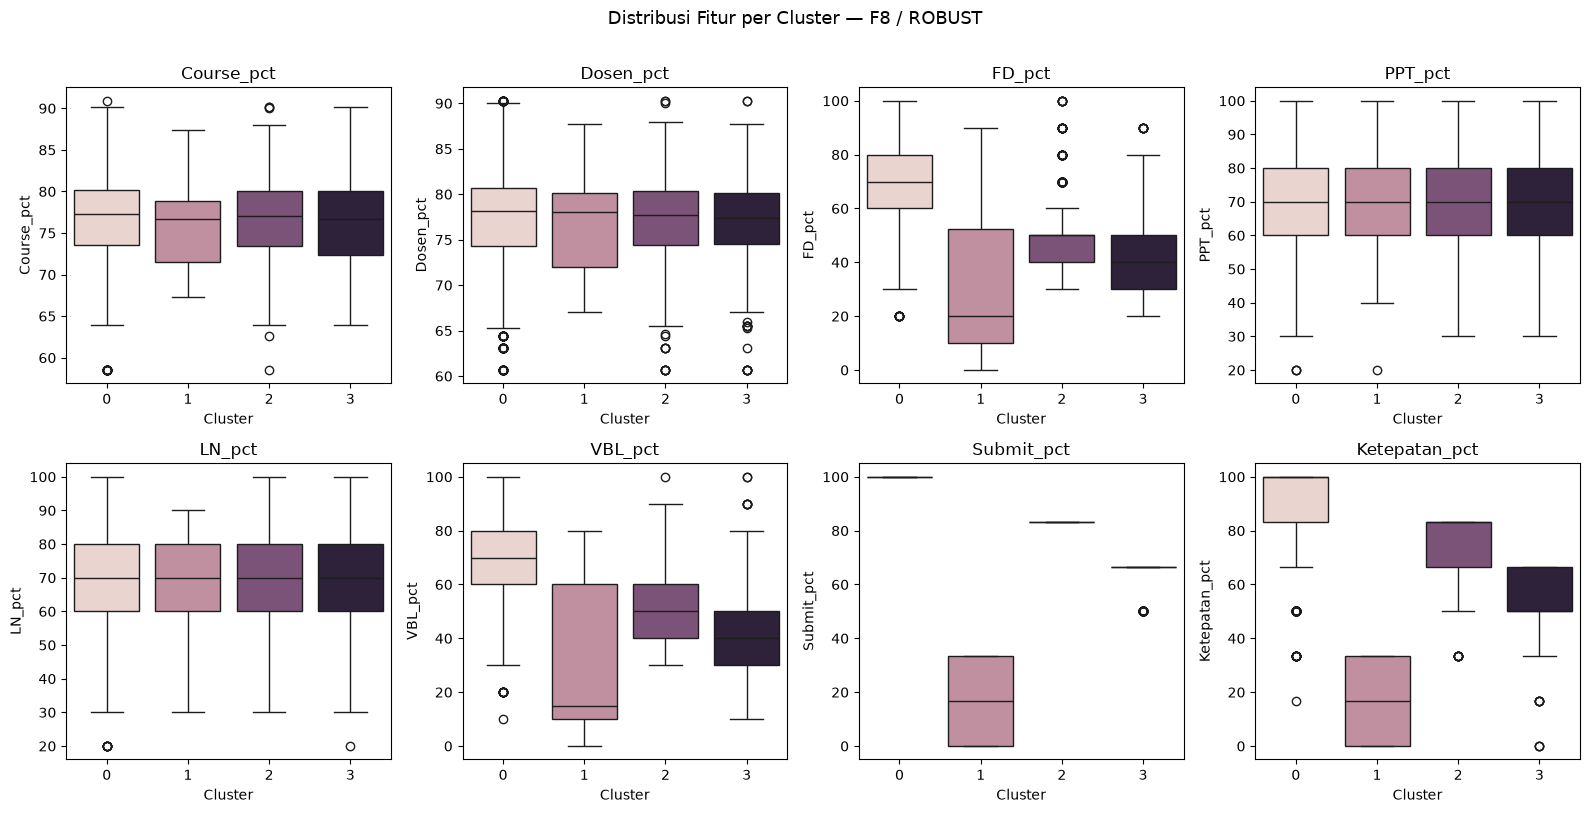

In [16]:
ncols = 4

nrows = int(
    np.ceil(
        len(
            CLUSTER_FEATURES
        )
        / ncols
    )
)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(
        16,
        nrows * 4,
    ),
)

axes_flat = np.asarray(
    axes
).reshape(
    -1
)

for ax, feature in zip(
    axes_flat,
    CLUSTER_FEATURES,
):
    sns.boxplot(
        data=df,
        x="Cluster",
        y=feature,
        hue="Cluster",
        legend=False,
        ax=ax,
    )

    ax.set_title(
        feature
    )

for ax in axes_flat[
    len(
        CLUSTER_FEATURES
    ):
]:
    ax.set_visible(
        False
    )

plt.suptitle(
    f"Distribusi Fitur per Cluster — "
    f"{ACTIVE_CASE} / {ACTIVE_TRANSFORM}",
    fontsize=13,
    y=1.01,
)

plt.tight_layout()
plt.show()


## 13. PCA 2D pada Ruang Setelah Preprocessing

PC1 variance       : 97.72%
PC2 variance       : 0.74%
PC1 + PC2 variance : 98.46%


,PC1_Loading,PC2_Loading
Course_pct,0.0023,0.6762
Dosen_pct,0.0024,0.7257
FD_pct,0.0230,0.0173
PPT_pct,0.0012,0.0035
LN_pct,0.0017,0.0299
VBL_pct,0.0344,0.0125
Submit_pct,0.9973,-0.0115
Ketepatan_pct,0.0601,0.1211


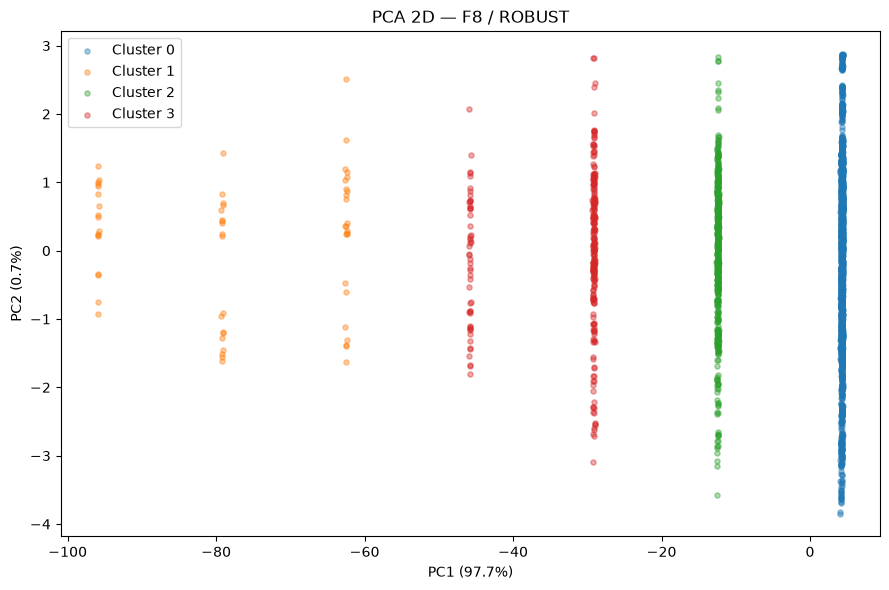

In [17]:
pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE,
)

X_pca = pca.fit_transform(
    X_transformed
)

pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=CLUSTER_FEATURES,
    columns=[
        "PC1_Loading",
        "PC2_Loading",
    ],
)

pca_variance = (
    pca.explained_variance_ratio_
    * 100
)

print(
    f"PC1 variance       : "
    f"{pca_variance[0]:.2f}%"
)

print(
    f"PC2 variance       : "
    f"{pca_variance[1]:.2f}%"
)

print(
    f"PC1 + PC2 variance : "
    f"{pca_variance.sum():.2f}%"
)

display(
    pca_loadings.round(
        4
    )
)

plt.figure(
    figsize=(
        9,
        6,
    )
)

for cluster_id in sorted(
    df[
        "Cluster"
    ]
    .unique()
):
    mask = (
        df[
            "Cluster"
        ]
        .to_numpy()
        == cluster_id
    )

    plt.scatter(
        X_pca[
            mask,
            0,
        ],
        X_pca[
            mask,
            1,
        ],
        s=14,
        alpha=0.4,
        label=(
            f"Cluster {cluster_id}"
        ),
    )

plt.xlabel(
    f"PC1 ({pca_variance[0]:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca_variance[1]:.1f}%)"
)

plt.title(
    f"PCA 2D — {ACTIVE_CASE} / {ACTIVE_TRANSFORM}"
)

plt.legend()
plt.tight_layout()
plt.show()


## 13b. Visualisasi Tambahan — UMAP, Radar Chart, dan Parallel Coordinates Plot

Visualisasi tambahan ini **tidak mengubah model K-Means, preprocessing, label cluster, maupun evaluasi yang sudah ada**.

- **UMAP** memakai `X_transformed`, yaitu feature space yang sama dengan K-Means.
- **Radar Chart** memakai empirical mean pada **skala asli** agar profil cluster mudah dibaca.
- **Parallel Coordinates Plot** juga memakai empirical mean pada **skala asli**.

> Catatan: UMAP adalah visual diagnostic. Bentuk/pemisahan pada plot UMAP tidak boleh dipakai sendirian sebagai bukti kualitas cluster.


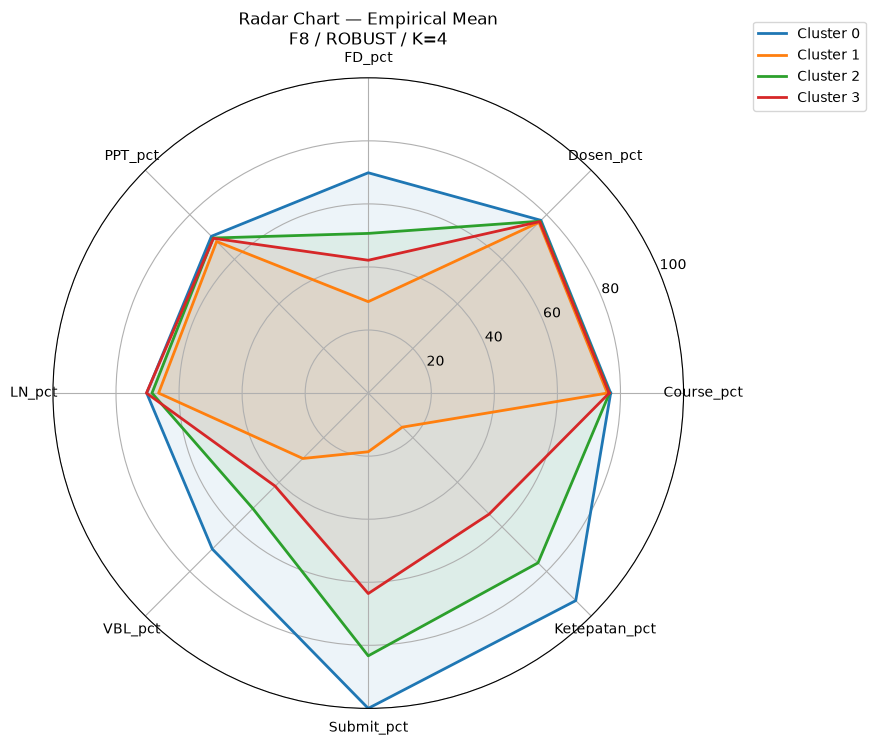

In [19]:
# ============================================================
# 13b-2. RADAR CHART — EMPIRICAL CLUSTER MEAN
# ============================================================
#
# Semua F8 berbentuk persentase 0–100, sehingga radar chart
# menggunakan skala asli agar interpretasinya tetap langsung.
# ============================================================

radar_profile = (
    empirical_profile_mean[
        CLUSTER_FEATURES
    ]
    .copy()
)

radar_features = list(
    CLUSTER_FEATURES
)

n_radar_features = len(
    radar_features
)

angles = np.linspace(
    0,
    2 * np.pi,
    n_radar_features,
    endpoint=False,
).tolist()

angles += angles[:1]


fig = plt.figure(
    figsize=(
        9,
        9,
    )
)

ax = fig.add_subplot(
    111,
    polar=True,
)


for cluster_id in radar_profile.index:

    values = (
        radar_profile.loc[
            cluster_id,
            radar_features,
        ]
        .to_numpy(
            dtype=float
        )
        .tolist()
    )

    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        label=f"Cluster {cluster_id}",
    )

    ax.fill(
        angles,
        values,
        alpha=0.08,
    )


ax.set_xticks(
    angles[:-1]
)

ax.set_xticklabels(
    radar_features
)

ax.set_ylim(
    0,
    100,
)

ax.set_yticks(
    [
        20,
        40,
        60,
        80,
        100,
    ]
)

ax.set_title(
    f"Radar Chart — Empirical Mean\n"
    f"{ACTIVE_CASE} / {ACTIVE_TRANSFORM} / K={K_FINAL}",
    pad=24,
)

ax.legend(
    loc="upper right",
    bbox_to_anchor=(
        1.30,
        1.10,
    ),
)

plt.tight_layout()
plt.show()


d:\Binus_Adhit_V1\Binus-Project\Binus-Project-Venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Binus_Adhit_V1\Binus-Project\Binus-Project-Venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Visualisasi menggunakan UMAP.


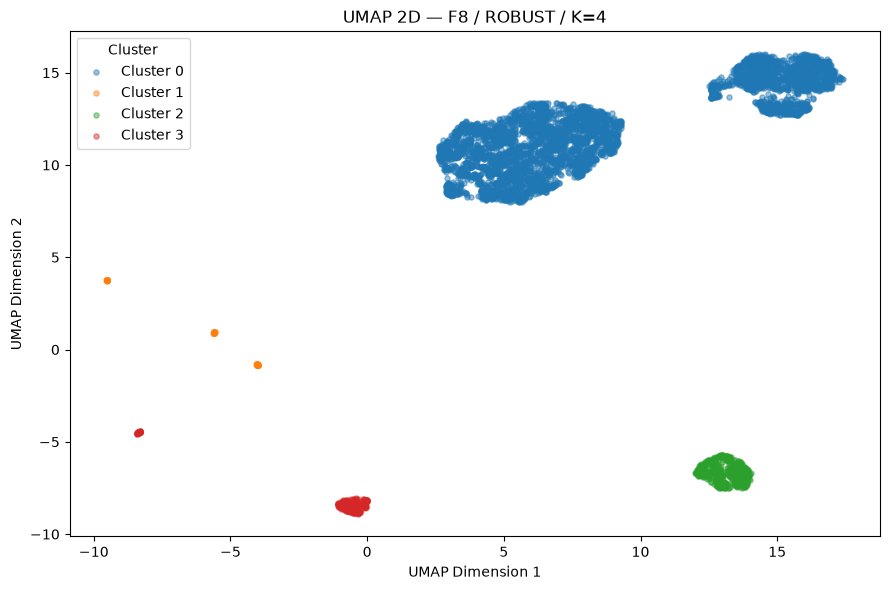

In [20]:
# ============================================================
# VISUALISASI 2D — UMAP DENGAN FALLBACK T-SNE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE


# ============================================================
# CONFIG
# ============================================================

USE_UMAP_IF_AVAILABLE = True

UMAP_N_NEIGHBORS = 30
UMAP_MIN_DIST = 0.10

TSNE_PERPLEXITY = 30
TSNE_MAX_ITER = 1000


# ============================================================
# TRY UMAP
# ============================================================

embedding_method = None
X_embedding = None


if USE_UMAP_IF_AVAILABLE:

    try:

        import umap.umap_ as umap

        umap_model = umap.UMAP(
            n_components=2,
            n_neighbors=UMAP_N_NEIGHBORS,
            min_dist=UMAP_MIN_DIST,
            metric="euclidean",
            random_state=RANDOM_STATE,
        )

        X_embedding = (
            umap_model.fit_transform(
                X_transformed
            )
        )

        embedding_method = "UMAP"

        print(
            "Visualisasi menggunakan UMAP."
        )

    except Exception as error:

        print(
            "UMAP tidak dapat dijalankan."
        )

        print(
            "Penyebab:",
            type(error).__name__,
            "-",
            str(error),
        )

        print(
            "\nFallback ke t-SNE..."
        )


# ============================================================
# FALLBACK T-SNE
# ============================================================

if X_embedding is None:

    tsne_model = TSNE(
        n_components=2,
        perplexity=TSNE_PERPLEXITY,
        max_iter=TSNE_MAX_ITER,
        init="pca",
        learning_rate="auto",
        random_state=RANDOM_STATE,
    )

    X_embedding = (
        tsne_model.fit_transform(
            X_transformed
        )
    )

    embedding_method = "t-SNE"

    print(
        "Visualisasi menggunakan t-SNE."
    )


# ============================================================
# DATAFRAME
# ============================================================

embedding_df = pd.DataFrame(
    {
        "Dim1": X_embedding[:, 0],
        "Dim2": X_embedding[:, 1],
        "Cluster": (
            df[
                "Cluster"
            ]
            .to_numpy()
        ),
    }
)


# ============================================================
# PLOT
# ============================================================

plt.figure(
    figsize=(
        9,
        6,
    )
)

for cluster_id in sorted(
    embedding_df[
        "Cluster"
    ]
    .unique()
):

    cluster_mask = (
        embedding_df[
            "Cluster"
        ]
        .to_numpy()
        == cluster_id
    )

    plt.scatter(
        embedding_df.loc[
            cluster_mask,
            "Dim1",
        ],
        embedding_df.loc[
            cluster_mask,
            "Dim2",
        ],
        s=14,
        alpha=0.45,
        label=f"Cluster {cluster_id}",
    )


plt.xlabel(
    f"{embedding_method} Dimension 1"
)

plt.ylabel(
    f"{embedding_method} Dimension 2"
)

plt.title(
    f"{embedding_method} 2D — "
    f"{ACTIVE_CASE} / "
    f"{ACTIVE_TRANSFORM} / "
    f"K={K_FINAL}"
)

plt.legend(
    title="Cluster"
)

plt.tight_layout()
plt.show()

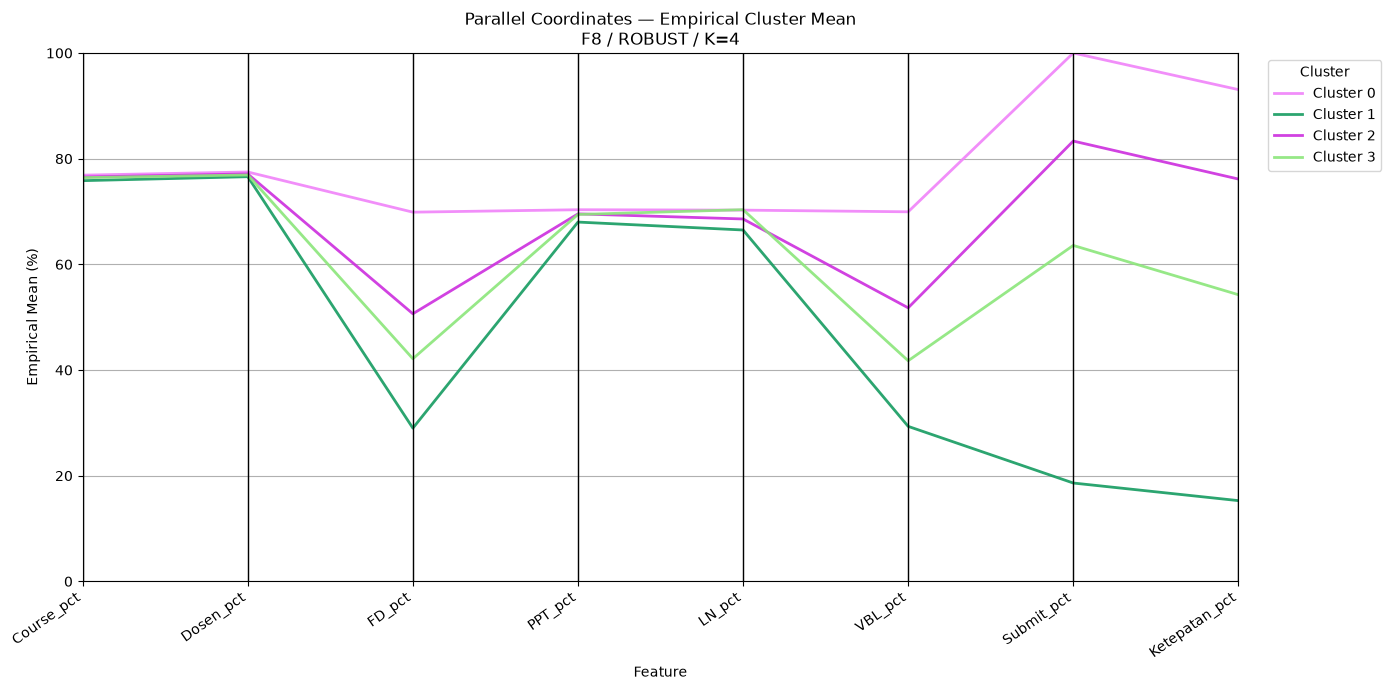

In [21]:
# ============================================================
# 13b-3. PARALLEL COORDINATES PLOT
# ============================================================
#
# Satu garis = empirical mean dari satu cluster.
# Karena seluruh F8 berada pada skala persentase 0–100,
# plot tetap memakai skala asli.
# ============================================================

from pandas.plotting import parallel_coordinates


parallel_profile = (
    empirical_profile_mean[
        CLUSTER_FEATURES
    ]
    .reset_index()
    .copy()
)

parallel_profile[
    "Cluster"
] = (
    "Cluster "
    + parallel_profile[
        "Cluster"
    ]
    .astype(
        str
    )
)


plt.figure(
    figsize=(
        14,
        7,
    )
)

parallel_coordinates(
    parallel_profile,
    class_column="Cluster",
    cols=CLUSTER_FEATURES,
    alpha=0.90,
    linewidth=2,
)

plt.ylim(
    0,
    100,
)

plt.xlabel(
    "Feature"
)

plt.ylabel(
    "Empirical Mean (%)"
)

plt.title(
    f"Parallel Coordinates — Empirical Cluster Mean\n"
    f"{ACTIVE_CASE} / {ACTIVE_TRANSFORM} / K={K_FINAL}"
)

plt.xticks(
    rotation=35,
    ha="right",
)

plt.legend(
    title="Cluster",
    bbox_to_anchor=(
        1.02,
        1,
    ),
    loc="upper left",
)

plt.tight_layout()
plt.show()


## 14. Silhouette per Cluster

In [22]:
sample_silhouette = silhouette_samples(
    X_transformed,
    labels_final,
)

silhouette_frame = pd.DataFrame(
    {
        "Cluster": (
            labels_final
        ),
        "Silhouette": (
            sample_silhouette
        ),
    }
)

silhouette_by_cluster = (
    silhouette_frame
    .groupby(
        "Cluster"
    )
    .agg(
        Mean_Silhouette=(
            "Silhouette",
            "mean",
        ),
        Median_Silhouette=(
            "Silhouette",
            "median",
        ),
        Minimum=(
            "Silhouette",
            "min",
        ),
        Maximum=(
            "Silhouette",
            "max",
        ),
        Negative_Percent=(
            "Silhouette",
            lambda values: (
                values
                < 0
            ).mean()
            * 100,
        ),
        Jumlah=(
            "Silhouette",
            "size",
        ),
    )
)

display(
    silhouette_by_cluster.round(
        5
    )
)

print(
    "Persentase seluruh record dengan "
    "Silhouette negatif:"
)

print(
    f"{(sample_silhouette < 0).mean() * 100:.2f}%"
)


,Mean_Silhouette,Median_Silhouette,Minimum,Maximum,Negative_Percent,Jumlah
Cluster,,,,,,
0,0.85386,0.85913,0.65217,0.89425,0.0,4820
1,0.61005,0.69058,0.44739,0.73342,0.0,60
2,0.85793,0.86299,0.72161,0.89557,0.0,559
3,0.65866,0.68286,0.53407,0.71975,0.0,286


Persentase seluruh record dengan Silhouette negatif:
0.00%


## 15. Feature Separation Diagnostic

`Eta_Squared` mengukur proporsi variasi tiap fitur asli yang berada **antarcluster**.
Nilai tinggi berarti hard cluster banyak membedakan fitur tersebut.


In [23]:
feature_separation_rows = []

for feature in CLUSTER_FEATURES:
    values = (
        df[
            feature
        ]
        .to_numpy(
            dtype=float
        )
    )

    overall_mean = (
        values.mean()
    )

    total_ss = np.sum(
        (
            values
            - overall_mean
        ) ** 2
    )

    between_ss = 0.0

    for cluster_id in sorted(
        df[
            "Cluster"
        ].unique()
    ):
        cluster_values = (
            df.loc[
                df[
                    "Cluster"
                ]
                == cluster_id,
                feature,
            ]
            .to_numpy(
                dtype=float
            )
        )

        between_ss += (
            len(
                cluster_values
            )
            * (
                cluster_values.mean()
                - overall_mean
            ) ** 2
        )

    eta_squared = (
        between_ss
        / total_ss
        if total_ss > 0
        else np.nan
    )

    feature_separation_rows.append(
        {
            "Feature": feature,
            "Eta_Squared": (
                eta_squared
            ),
            "Between_Variance_Percent": (
                eta_squared
                * 100
            ),
        }
    )

feature_separation = (
    pd.DataFrame(
        feature_separation_rows
    )
    .sort_values(
        "Eta_Squared",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)

display(
    feature_separation.round(
        5
    )
)


,Feature,Eta_Squared,Between_Variance_Percent
0,Submit_pct,0.97274,97.27393
1,Ketepatan_pct,0.52658,52.65796
2,FD_pct,0.26095,26.09524
3,VBL_pct,0.25455,25.45536
4,LN_pct,0.00183,0.18274
5,Dosen_pct,0.00132,0.13167
6,Course_pct,0.00122,0.12153
7,PPT_pct,0.00067,0.06734


## 16. Random-Seed Stability

In [24]:
seed_stability_rows = []

for run_index in range(
    SEED_STABILITY_RUNS
):
    seed = (
        RANDOM_STATE
        + run_index
        + 1
    )

    model_seed = KMeans(
        n_clusters=K_FINAL,
        random_state=seed,
        n_init=SEARCH_N_INIT,
        max_iter=MAX_ITER,
    )

    labels_seed = (
        model_seed
        .fit_predict(
            X_transformed
        )
    )

    sizes_seed = cluster_size_metrics(
        labels_seed
    )

    seed_stability_rows.append(
        {
            "Run": (
                run_index
                + 1
            ),
            "Random_State": (
                seed
            ),
            "ARI_vs_Final": (
                adjusted_rand_score(
                    labels_final,
                    labels_seed,
                )
            ),
            **sizes_seed,
        }
    )

seed_stability = pd.DataFrame(
    seed_stability_rows
)

display(
    seed_stability.round(
        5
    )
)

print(
    f"Seed ARI mean: "
    f"{seed_stability['ARI_vs_Final'].mean():.5f}"
)

print(
    f"Seed ARI std : "
    f"{seed_stability['ARI_vs_Final'].std():.5f}"
)


,Run,Random_State,ARI_vs_Final,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Share
0,1,43,1.0,60,4820,0.84192
1,2,44,1.0,60,4820,0.84192
2,3,45,1.0,60,4820,0.84192
3,4,46,1.0,60,4820,0.84192
4,5,47,1.0,60,4820,0.84192
5,6,48,1.0,60,4820,0.84192
6,7,49,1.0,60,4820,0.84192
7,8,50,1.0,60,4820,0.84192
8,9,51,1.0,60,4820,0.84192
9,10,52,1.0,60,4820,0.84192


Seed ARI mean: 1.00000
Seed ARI std : 0.00000


## SANITY TEST

In [25]:
# ============================================================
# SANITY TEST — K-MEANS REPEATED FIT
# Different random initialization, same data & configuration
# ============================================================

from scipy.optimize import linear_sum_assignment


SANITY_TEST_RUNS = 10

sanity_rows = []


def align_cluster_labels(
    reference_labels,
    candidate_labels,
):
    """
    Align label candidate ke label reference menggunakan
    Hungarian matching.

    Contoh:
    final C0 mungkin muncul sebagai C2 pada run lain.
    Fungsi ini akan memetakannya kembali supaya kolom
    C0, C1, C2, C3 tetap comparable.
    """

    reference_labels = np.asarray(
        reference_labels
    )

    candidate_labels = np.asarray(
        candidate_labels
    )

    reference_clusters = np.unique(
        reference_labels
    )

    candidate_clusters = np.unique(
        candidate_labels
    )

    contingency = pd.crosstab(
        reference_labels,
        candidate_labels,
    )

    contingency = (
        contingency
        .reindex(
            index=reference_clusters,
            columns=candidate_clusters,
            fill_value=0,
        )
    )

    # Hungarian algorithm:
    # maximize overlap = minimize negative overlap
    row_ind, col_ind = (
        linear_sum_assignment(
            -contingency.to_numpy()
        )
    )

    mapping = {
        candidate_clusters[
            candidate_index
        ]:
        reference_clusters[
            reference_index
        ]
        for reference_index, candidate_index
        in zip(
            row_ind,
            col_ind,
        )
    }

    aligned_labels = np.array(
        [
            mapping.get(
                label,
                label,
            )
            for label in candidate_labels
        ]
    )

    return aligned_labels


for iteration in range(
    1,
    SANITY_TEST_RUNS + 1,
):

    # --------------------------------------------------------
    # Random state berbeda setiap iteration
    # --------------------------------------------------------
    sanity_seed = (
        RANDOM_STATE
        + iteration
    )

    sanity_model = KMeans(
        n_clusters=K_FINAL,
        random_state=sanity_seed,
        n_init=FINAL_N_INIT,
        max_iter=MAX_ITER,
    )

    # --------------------------------------------------------
    # Fit ulang pada DATA YANG SAMA
    # --------------------------------------------------------
    sanity_labels_raw = (
        sanity_model
        .fit_predict(
            X_transformed
        )
    )

    # --------------------------------------------------------
    # ARI terhadap final clustering
    #
    # ARI sebenarnya tidak perlu label alignment karena
    # invariant terhadap pergantian nomor cluster.
    # --------------------------------------------------------
    sanity_ari = (
        adjusted_rand_score(
            labels_final,
            sanity_labels_raw,
        )
    )

    # --------------------------------------------------------
    # Align label supaya C0/C1/C2/C3 dapat dibandingkan
    # langsung dengan final model.
    # --------------------------------------------------------
    sanity_labels = (
        align_cluster_labels(
            labels_final,
            sanity_labels_raw,
        )
    )

    # --------------------------------------------------------
    # Hitung jumlah anggota masing-masing cluster
    # --------------------------------------------------------
    cluster_counts = (
        pd.Series(
            sanity_labels
        )
        .value_counts()
        .reindex(
            range(
                K_FINAL
            ),
            fill_value=0,
        )
        .sort_index()
    )

    row = {
        "Iteration": iteration,
        "ARI": sanity_ari,
    }

    for cluster_id in range(
        K_FINAL
    ):
        row[
            f"C{cluster_id}"
        ] = int(
            cluster_counts[
                cluster_id
            ]
        )

    sanity_rows.append(
        row
    )


# ============================================================
# HASIL SANITY TEST
# ============================================================

sanity_test = pd.DataFrame(
    sanity_rows
)

display(
    sanity_test.round(
        {
            "ARI": 5,
        }
    )
)


# ============================================================
# SUMMARY
# ============================================================

print(
    "=" * 70
)

print(
    "SANITY TEST SUMMARY"
)

print(
    "=" * 70
)

print(
    f"Runs             : "
    f"{SANITY_TEST_RUNS}"
)

print(
    f"ARI mean         : "
    f"{sanity_test['ARI'].mean():.5f}"
)

print(
    f"ARI std          : "
    f"{sanity_test['ARI'].std():.5f}"
)

print(
    f"ARI min          : "
    f"{sanity_test['ARI'].min():.5f}"
)

print(
    f"ARI max          : "
    f"{sanity_test['ARI'].max():.5f}"
)

print(
    "=" * 70
)

,Iteration,ARI,C0,C1,C2,C3
0,1,1.0,4820,60,559,286
1,2,1.0,4820,60,559,286
2,3,1.0,4820,60,559,286
3,4,1.0,4820,60,559,286
4,5,1.0,4820,60,559,286
5,6,1.0,4820,60,559,286
6,7,1.0,4820,60,559,286
7,8,1.0,4820,60,559,286
8,9,1.0,4820,60,559,286
9,10,1.0,4820,60,559,286


SANITY TEST SUMMARY
Runs             : 10
ARI mean         : 1.00000
ARI std          : 0.00000
ARI min          : 1.00000
ARI max          : 1.00000


## 17. Grouped-NIM Stability

Karena satu NIM muncul pada beberapa student-course record, stability juga diuji dengan
resampling pada level **NIM**, bukan hanya record.

Setiap run:

1. ambil 80% NIM unik,
2. fit preprocessing pada subset,
3. fit K-Means pada subset,
4. transform + predict seluruh dataset,
5. hitung ARI terhadap assignment final.


In [26]:
group_rng = np.random.default_rng(
    RANDOM_STATE
)

unique_nims = (
    df[
        "NIM"
    ]
    .dropna()
    .unique()
)

sample_nim_count = int(
    np.floor(
        len(
            unique_nims
        )
        * GROUPED_NIM_FRACTION
    )
)

grouped_nim_rows = []

for run_index in range(
    GROUPED_NIM_RUNS
):
    sampled_nims = group_rng.choice(
        unique_nims,
        size=sample_nim_count,
        replace=False,
    )

    train_mask = (
        df[
            "NIM"
        ]
        .isin(
            sampled_nims
        )
        .to_numpy()
    )

    X_train_raw = (
        df.loc[
            train_mask,
            CLUSTER_FEATURES,
        ]
        .to_numpy(
            dtype=float
        )
    )

    X_all_raw = (
        df[
            CLUSTER_FEATURES
        ]
        .to_numpy(
            dtype=float
        )
    )

    preprocessor_run = build_preprocessor(
        ACTIVE_TRANSFORM,
        len(
            X_train_raw
        ),
    )

    X_train_run = (
        preprocessor_run
        .fit_transform(
            X_train_raw
        )
    )

    X_all_run = (
        preprocessor_run
        .transform(
            X_all_raw
        )
    )

    model_run = KMeans(
        n_clusters=K_FINAL,
        random_state=(
            RANDOM_STATE
            + 100
            + run_index
        ),
        n_init=SEARCH_N_INIT,
        max_iter=MAX_ITER,
    )

    model_run.fit(
        X_train_run
    )

    labels_run_all = (
        model_run
        .predict(
            X_all_run
        )
    )

    sizes_run = cluster_size_metrics(
        labels_run_all
    )

    grouped_nim_rows.append(
        {
            "Run": (
                run_index
                + 1
            ),
            "Train_NIM_Count": (
                sample_nim_count
            ),
            "Train_Record_Count": int(
                train_mask.sum()
            ),
            "ARI_vs_Final": (
                adjusted_rand_score(
                    labels_final,
                    labels_run_all,
                )
            ),
            **sizes_run,
        }
    )

grouped_nim_stability = pd.DataFrame(
    grouped_nim_rows
)

display(
    grouped_nim_stability.round(
        5
    )
)

print(
    f"Grouped-NIM ARI mean: "
    f"{grouped_nim_stability['ARI_vs_Final'].mean():.5f}"
)

print(
    f"Grouped-NIM ARI std : "
    f"{grouped_nim_stability['ARI_vs_Final'].std():.5f}"
)

print(
    f"Grouped-NIM ARI min : "
    f"{grouped_nim_stability['ARI_vs_Final'].min():.5f}"
)


,Run,Train_NIM_Count,Train_Record_Count,ARI_vs_Final,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Share
0,1,466,4565,1.0,60,4820,0.84192
1,2,466,4455,1.0,60,4820,0.84192
2,3,466,4707,1.0,60,4820,0.84192
3,4,466,4624,1.0,60,4820,0.84192
4,5,466,4426,1.0,60,4820,0.84192
5,6,466,4521,1.0,60,4820,0.84192
6,7,466,4662,1.0,60,4820,0.84192
7,8,466,4602,1.0,60,4820,0.84192
8,9,466,4722,1.0,60,4820,0.84192
9,10,466,4549,1.0,60,4820,0.84192


Grouped-NIM ARI mean: 1.00000
Grouped-NIM ARI std : 0.00000
Grouped-NIM ARI min : 1.00000


,Run,Bootstrap_Record_Count,Unique_NIM_Selected,ARI_vs_Final,Silhouette,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Share
0,1,5719,389,1.0,0.84388,60,4820,0.84192
1,2,5540,357,1.0,0.83742,60,4820,0.84192
2,3,5942,364,1.0,0.83772,60,4820,0.84192
3,4,5742,373,1.0,0.84153,60,4820,0.84192
4,5,5843,373,1.0,0.83364,60,4820,0.84192
5,6,5719,369,1.0,0.85102,60,4820,0.84192
6,7,5600,354,1.0,0.83435,60,4820,0.84192
7,8,5778,359,1.0,0.83414,60,4820,0.84192
8,9,5566,370,1.0,0.84203,60,4820,0.84192
9,10,5949,371,1.0,0.83652,60,4820,0.84192



BOOTSTRAP STABILITY SUMMARY


,ARI_vs_Final,Silhouette,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Share
mean,1.0,0.84103,60.0,4820.0,0.84192
std,0.0,0.00555,0.0,0.0,0.00000
min,1.0,0.83358,60.0,4820.0,0.84192
max,1.0,0.85102,60.0,4820.0,0.84192


Bootstrap ARI mean : 1.00000
Bootstrap ARI std  : 0.00000
Bootstrap ARI min  : 1.00000
Bootstrap Sil mean : 0.84103
Bootstrap Sil std  : 0.00555


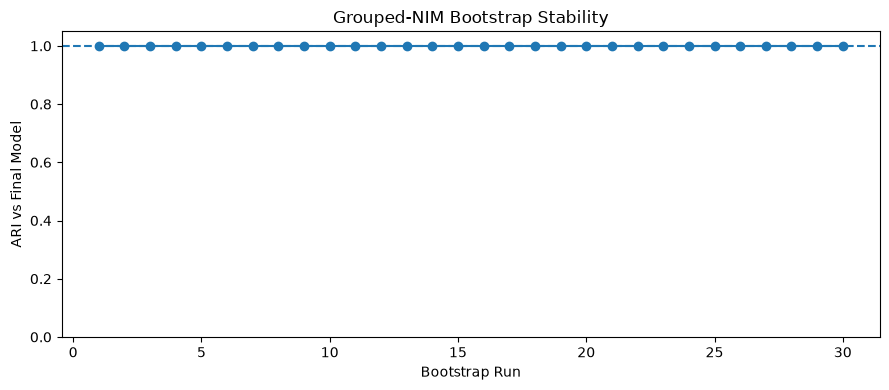

In [27]:
# ============================================================
# 17b. GROUPED-NIM BOOTSTRAP STABILITY
# ============================================================

N_BOOTSTRAP = 30
BOOTSTRAP_SILHOUETTE_SAMPLE = 2000

bootstrap_rng = np.random.default_rng(
    RANDOM_STATE + 2026
)

# Data asli seluruh record
X_all_raw = (
    df[
        CLUSTER_FEATURES
    ]
    .to_numpy(
        dtype=float
    )
)

# Daftar NIM unik
unique_nims_boot = (
    df[
        "NIM"
    ]
    .dropna()
    .unique()
)

nim_array = (
    df[
        "NIM"
    ]
    .to_numpy()
)

# Mapping NIM -> index record
nim_to_indices = {
    nim: np.flatnonzero(
        nim_array == nim
    )
    for nim in unique_nims_boot
}

bootstrap_rows = []

for run_index in range(
    N_BOOTSTRAP
):
    # --------------------------------------------------------
    # 1. Bootstrap NIM dengan replacement
    # --------------------------------------------------------
    sampled_nims = (
        bootstrap_rng.choice(
            unique_nims_boot,
            size=len(
                unique_nims_boot
            ),
            replace=True,
        )
    )

    # Jika NIM terambil lebih dari sekali,
    # seluruh student-course records NIM tersebut ikut
    # terduplikasi dalam bootstrap sample.
    bootstrap_indices = np.concatenate(
        [
            nim_to_indices[nim]
            for nim in sampled_nims
        ]
    )

    X_boot_raw = (
        X_all_raw[
            bootstrap_indices
        ]
    )

    # --------------------------------------------------------
    # 2. Fit preprocessing dari bootstrap sample
    # --------------------------------------------------------
    preprocessor_boot = (
        build_preprocessor(
            ACTIVE_TRANSFORM,
            len(
                X_boot_raw
            ),
        )
    )

    X_boot = (
        preprocessor_boot
        .fit_transform(
            X_boot_raw
        )
    )

    # Transform seluruh dataset dengan scaler bootstrap
    X_all_boot_space = (
        preprocessor_boot
        .transform(
            X_all_raw
        )
    )

    # --------------------------------------------------------
    # 3. Fit K-Means pada bootstrap sample
    # --------------------------------------------------------
    kmeans_boot = KMeans(
        n_clusters=K_FINAL,
        random_state=(
            RANDOM_STATE
            + 1000
            + run_index
        ),
        n_init=FINAL_N_INIT,
        max_iter=MAX_ITER,
    )

    kmeans_boot.fit(
        X_boot
    )

    # --------------------------------------------------------
    # 4. Predict seluruh dataset
    # --------------------------------------------------------
    labels_boot_all = (
        kmeans_boot.predict(
            X_all_boot_space
        )
    )

    # --------------------------------------------------------
    # 5. ARI terhadap model final
    # --------------------------------------------------------
    ari_boot = (
        adjusted_rand_score(
            labels_final,
            labels_boot_all,
        )
    )

    # --------------------------------------------------------
    # 6. Silhouette pada model bootstrap
    #    menggunakan sample agar tidak terlalu berat
    # --------------------------------------------------------
    if len(
        np.unique(
            labels_boot_all
        )
    ) >= 2:

        sil_boot = (
            silhouette_score(
                X_all_boot_space,
                labels_boot_all,
                sample_size=min(
                    BOOTSTRAP_SILHOUETTE_SAMPLE,
                    len(
                        X_all_boot_space
                    ),
                ),
                random_state=(
                    RANDOM_STATE
                    + run_index
                ),
            )
        )

    else:
        sil_boot = np.nan

    # --------------------------------------------------------
    # 7. Cluster-size diagnostics
    # --------------------------------------------------------
    size_info = (
        cluster_size_metrics(
            labels_boot_all
        )
    )

    bootstrap_rows.append(
        {
            "Run": (
                run_index
                + 1
            ),
            "Bootstrap_Record_Count": (
                len(
                    bootstrap_indices
                )
            ),
            "Unique_NIM_Selected": (
                len(
                    np.unique(
                        sampled_nims
                    )
                )
            ),
            "ARI_vs_Final": (
                ari_boot
            ),
            "Silhouette": (
                sil_boot
            ),
            **size_info,
        }
    )


bootstrap_stability = (
    pd.DataFrame(
        bootstrap_rows
    )
)


# ============================================================
# SUMMARY
# ============================================================

display(
    bootstrap_stability.round(
        5
    )
)

bootstrap_summary = (
    bootstrap_stability[
        [
            "ARI_vs_Final",
            "Silhouette",
            "Smallest_Cluster",
            "Largest_Cluster",
            "Largest_Cluster_Share",
        ]
    ]
    .agg(
        [
            "mean",
            "std",
            "min",
            "max",
        ]
    )
)

print(
    "\nBOOTSTRAP STABILITY SUMMARY"
)

display(
    bootstrap_summary.round(
        5
    )
)

print(
    f"Bootstrap ARI mean : "
    f"{bootstrap_stability['ARI_vs_Final'].mean():.5f}"
)

print(
    f"Bootstrap ARI std  : "
    f"{bootstrap_stability['ARI_vs_Final'].std():.5f}"
)

print(
    f"Bootstrap ARI min  : "
    f"{bootstrap_stability['ARI_vs_Final'].min():.5f}"
)

print(
    f"Bootstrap Sil mean : "
    f"{bootstrap_stability['Silhouette'].mean():.5f}"
)

print(
    f"Bootstrap Sil std  : "
    f"{bootstrap_stability['Silhouette'].std():.5f}"
)


# ============================================================
# VISUALISASI
# ============================================================

plt.figure(
    figsize=(
        9,
        4,
    )
)

plt.plot(
    bootstrap_stability[
        "Run"
    ],
    bootstrap_stability[
        "ARI_vs_Final"
    ],
    marker="o",
)

plt.axhline(
    1.0,
    linestyle="--",
)

plt.xlabel(
    "Bootstrap Run"
)

plt.ylabel(
    "ARI vs Final Model"
)

plt.title(
    "Grouped-NIM Bootstrap Stability"
)

plt.ylim(
    0,
    1.05,
)

plt.tight_layout()
plt.show()

## 18. External Profile

In [28]:
if EXTERNAL_PROFILE_FEATURES:
    external_profile_mean = (
        df.groupby(
            "Cluster"
        )[
            EXTERNAL_PROFILE_FEATURES
        ]
        .mean()
    )

    external_profile_median = (
        df.groupby(
            "Cluster"
        )[
            EXTERNAL_PROFILE_FEATURES
        ]
        .median()
    )

    external_profile_std = (
        df.groupby(
            "Cluster"
        )[
            EXTERNAL_PROFILE_FEATURES
        ]
        .std()
    )

    print(
        "External profile mean:"
    )

    display(
        external_profile_mean.round(
            3
        )
    )

    print(
        "External profile median:"
    )

    display(
        external_profile_median.round(
            3
        )
    )

    print(
        "External profile std:"
    )

    display(
        external_profile_std.round(
            3
        )
    )

else:
    external_profile_mean = (
        pd.DataFrame()
    )

    external_profile_median = (
        pd.DataFrame()
    )

    external_profile_std = (
        pd.DataFrame()
    )

    print(
        "Tidak ada external numeric feature untuk F12."
    )


External profile mean:


,avg_LO1,avg_LO2,avg_LO3,Total_LO
Cluster,,,,
0,30.771,37.931,17.868,86.571
1,6.924,5.498,2.656,15.078
2,24.424,31.039,15.246,70.709
3,14.195,21.166,9.912,45.272


External profile median:


,avg_LO1,avg_LO2,avg_LO3,Total_LO
Cluster,,,,
0,31.444,38.333,18.333,87.778
1,7.167,5.556,0.000,12.167
2,24.222,31.000,15.667,72.222
3,11.111,21.111,9.444,43.333


External profile std:


,avg_LO1,avg_LO2,avg_LO3,Total_LO
Cluster,,,,
0,3.241,3.250,2.144,7.752
1,7.455,5.488,3.478,13.782
2,5.415,5.709,3.464,9.595
3,6.916,5.020,3.675,11.800


Jumlah record analisis : 5,725
NIM unik              : 583

UNIVARIATE CORRELATION


,Feature,Outcome,Pearson_r,Spearman_r
27,Submit_pct,Total_LO,0.8187,0.5657
31,Ketepatan_pct,Total_LO,0.7381,0.5036
23,VBL_pct,Total_LO,0.4071,0.2531
11,FD_pct,Total_LO,0.4069,0.2576
3,Course_pct,Total_LO,0.0965,0.0944
7,Dosen_pct,Total_LO,0.0900,0.0772
15,PPT_pct,Total_LO,0.0202,0.0123
19,LN_pct,Total_LO,0.0158,0.0166
24,Submit_pct,avg_LO1,0.7485,0.5007
28,Ketepatan_pct,avg_LO1,0.6886,0.4634



MULTICOLLINEARITY — VIF


,Feature,VIF
0,Course_pct,10.152
1,Dosen_pct,10.084
2,Submit_pct,2.657
3,Ketepatan_pct,2.180
4,FD_pct,1.348
5,VBL_pct,1.342
6,LN_pct,1.003
7,PPT_pct,1.002



MODEL SUMMARY


,Outcome,R2,Adjusted_R2,N
0,avg_LO1,0.6055,0.6049,5725
1,avg_LO2,0.7006,0.7002,5725
2,avg_LO3,0.5108,0.5101,5725
3,Total_LO,0.7145,0.7141,5725



STANDARDIZED MULTIVARIATE ASSOCIATION


,Outcome,Feature,Beta_Std,Std_Error_ClusterNIM,z_value,p_value,CI95_Lower,CI95_Upper,R2_Model,p_value_FDR_BH,Significant_FDR_005,Abs_Beta_Std
30,Total_LO,Submit_pct,0.59517,0.01931,30.82508,0.00000,0.55733,0.63302,0.71450,0.00000,True,0.59517
31,Total_LO,Ketepatan_pct,0.29381,0.01390,21.13495,0.00000,0.26656,0.32105,0.71450,0.00000,True,0.29381
24,Total_LO,Course_pct,0.03072,0.02346,1.30967,0.19031,-0.01525,0.07669,0.71450,0.43257,False,0.03072
25,Total_LO,Dosen_pct,0.01071,0.02259,0.47439,0.63522,-0.03355,0.05498,0.71450,0.78181,False,0.01071
29,Total_LO,VBL_pct,0.00992,0.00852,1.16343,0.24465,-0.00679,0.02663,0.71450,0.44853,False,0.00992
28,Total_LO,LN_pct,-0.00984,0.00718,-1.37049,0.17053,-0.02391,0.00423,0.71450,0.41978,False,0.00984
26,Total_LO,FD_pct,0.00616,0.00811,0.75902,0.44784,-0.00974,0.02206,0.71450,0.65141,False,0.00616
27,Total_LO,PPT_pct,0.00431,0.00703,0.61319,0.53975,-0.00946,0.01808,0.71450,0.71967,False,0.00431
6,avg_LO1,Submit_pct,0.51557,0.02481,20.77734,0.00000,0.46694,0.56421,0.60550,0.00000,True,0.51557
7,avg_LO1,Ketepatan_pct,0.29899,0.01382,21.63085,0.00000,0.27190,0.32609,0.60550,0.00000,True,0.29899



STANDARDIZED BETA MATRIX


Outcome,Total_LO,avg_LO1,avg_LO2,avg_LO3
Feature,,,,
Course_pct,0.0307,0.0070,0.0303,0.0635
Dosen_pct,0.0107,0.0278,0.0133,-0.0275
FD_pct,0.0062,0.0165,-0.0006,-0.0013
PPT_pct,0.0043,-0.0001,0.0020,0.0150
LN_pct,-0.0098,-0.0138,-0.0061,-0.0067
VBL_pct,0.0099,0.0123,0.0108,0.0011
Submit_pct,0.5952,0.5156,0.6036,0.5326
Ketepatan_pct,0.2938,0.2990,0.2779,0.2221


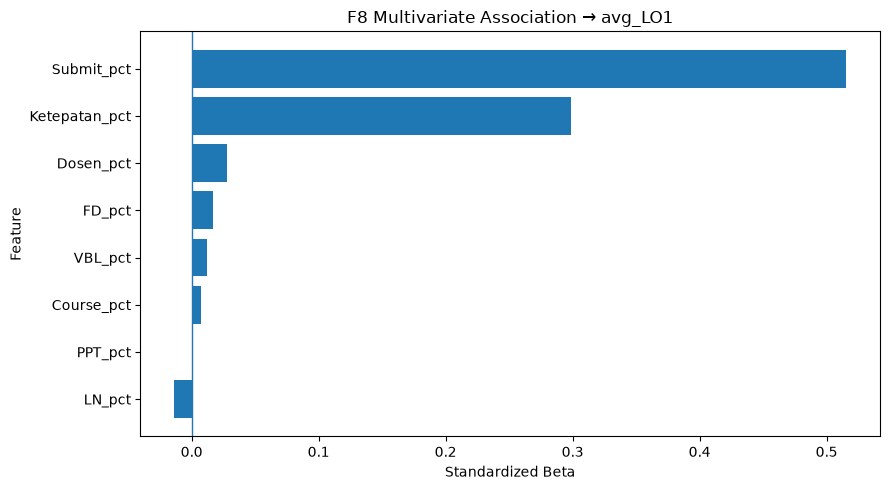

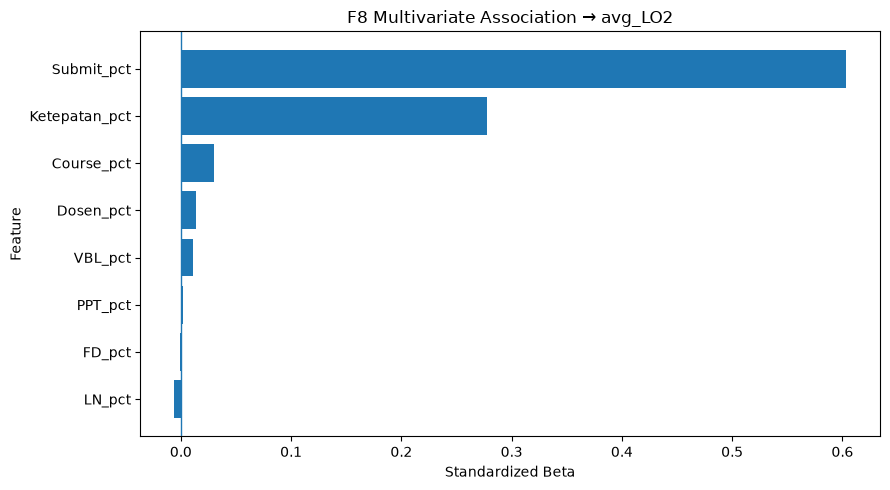

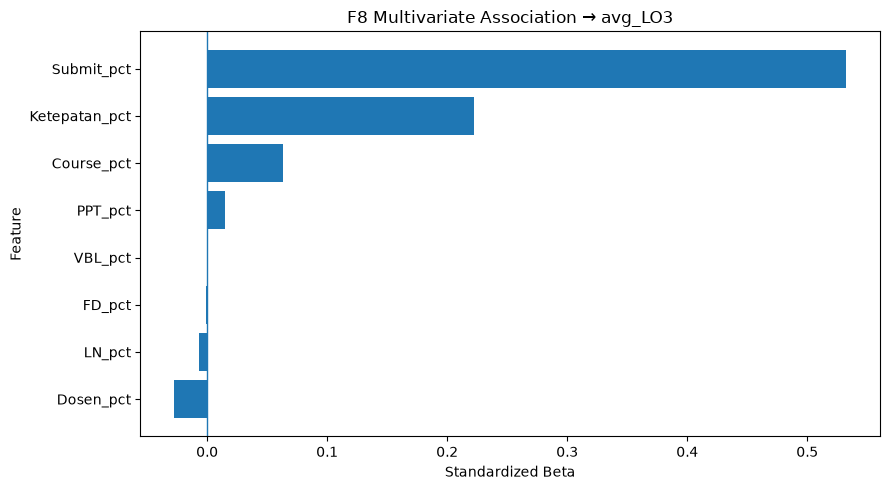

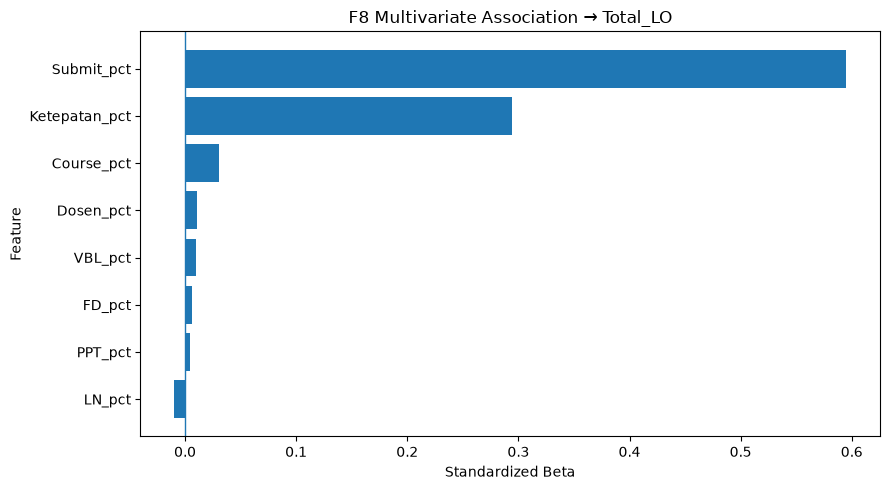

In [29]:
# ============================================================
# 18b. F8 FEATURES -> LO ASSOCIATION ANALYSIS
# ============================================================
#
# Tujuan:
# Menilai hubungan masing-masing dari 8 fitur F8 terhadap:
# - avg_LO1
# - avg_LO2
# - avg_LO3
# - Total_LO
#
# Analisis:
# 1. Pearson correlation
# 2. Spearman correlation
# 3. Multivariate standardized OLS
# 4. Cluster-robust standard error by NIM
# 5. FDR correction untuk multiple testing
# 6. VIF untuk multicollinearity diagnostic
#
# CATATAN:
# Interpretasi = asosiasi, BUKAN kausalitas.
# ============================================================

import statsmodels.api as sm

from sklearn.preprocessing import StandardScaler

from statsmodels.stats.multitest import (
    multipletests,
)

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor,
)


# ============================================================
# FEATURE DAN OUTCOME
# ============================================================

F8_FEATURES = [
    "Course_pct",
    "Dosen_pct",
    "FD_pct",
    "PPT_pct",
    "LN_pct",
    "VBL_pct",
    "Submit_pct",
    "Ketepatan_pct",
]

LO_TARGETS = [
    "avg_LO1",
    "avg_LO2",
    "avg_LO3",
    "Total_LO",
]


# ============================================================
# VALIDASI
# ============================================================

required_analysis_columns = (
    F8_FEATURES
    + LO_TARGETS
    + [
        "NIM"
    ]
)

missing_columns = [
    column
    for column in required_analysis_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Kolom tidak ditemukan: "
        f"{missing_columns}"
    )


analysis_df = (
    df[
        required_analysis_columns
    ]
    .dropna()
    .copy()
)

print(
    f"Jumlah record analisis : "
    f"{len(analysis_df):,}"
)

print(
    f"NIM unik              : "
    f"{analysis_df['NIM'].nunique():,}"
)


# ============================================================
# A. UNIVARIATE CORRELATION
# ============================================================

correlation_rows = []

for feature in F8_FEATURES:

    for target in LO_TARGETS:

        pearson_r = (
            analysis_df[
                [
                    feature,
                    target,
                ]
            ]
            .corr(
                method="pearson"
            )
            .iloc[
                0,
                1,
            ]
        )

        spearman_r = (
            analysis_df[
                [
                    feature,
                    target,
                ]
            ]
            .corr(
                method="spearman"
            )
            .iloc[
                0,
                1,
            ]
        )

        correlation_rows.append(
            {
                "Feature": feature,
                "Outcome": target,
                "Pearson_r": (
                    pearson_r
                ),
                "Spearman_r": (
                    spearman_r
                ),
            }
        )


lo_correlation_table = (
    pd.DataFrame(
        correlation_rows
    )
)

print(
    "\nUNIVARIATE CORRELATION"
)

display(
    lo_correlation_table
    .sort_values(
        [
            "Outcome",
            "Pearson_r",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .round(
        4
    )
)


# ============================================================
# B. STANDARDIZE X
# ============================================================
#
# StandardScaler dipakai DI SINI hanya untuk membuat
# coefficient antar-feature comparable.
#
# Ini terpisah dari preprocessing K-Means.
# ============================================================

X_raw_regression = (
    analysis_df[
        F8_FEATURES
    ]
    .to_numpy(
        dtype=float
    )
)

x_scaler = StandardScaler()

X_standardized = (
    x_scaler.fit_transform(
        X_raw_regression
    )
)

X_regression = (
    pd.DataFrame(
        X_standardized,
        columns=F8_FEATURES,
        index=analysis_df.index,
    )
)

X_design = (
    sm.add_constant(
        X_regression,
        has_constant="add",
    )
)


# ============================================================
# C. VIF DIAGNOSTIC
# ============================================================

vif_rows = []

for feature_index, feature in enumerate(
    F8_FEATURES
):

    vif_value = (
        variance_inflation_factor(
            X_standardized,
            feature_index,
        )
    )

    vif_rows.append(
        {
            "Feature": feature,
            "VIF": (
                vif_value
            ),
        }
    )


vif_table = (
    pd.DataFrame(
        vif_rows
    )
    .sort_values(
        "VIF",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)

print(
    "\nMULTICOLLINEARITY — VIF"
)

display(
    vif_table.round(
        3
    )
)


# ============================================================
# D. MULTIVARIATE OLS
# ============================================================
#
# Outcome juga distandardisasi.
#
# Maka beta dapat dibaca:
# kenaikan 1 SD feature berasosiasi dengan perubahan beta SD
# pada LO, dengan 7 feature lain dikontrol.
#
# Standard error dibuat cluster-robust berdasarkan NIM
# karena satu NIM memiliki beberapa student-course records.
# ============================================================

regression_rows = []
model_summary_rows = []

groups = (
    analysis_df[
        "NIM"
    ]
    .to_numpy()
)

for target in LO_TARGETS:

    y_raw = (
        analysis_df[
            target
        ]
        .to_numpy(
            dtype=float
        )
    )

    y_mean = (
        y_raw.mean()
    )

    y_std = (
        y_raw.std(
            ddof=0
        )
    )

    if np.isclose(
        y_std,
        0.0,
    ):
        raise ValueError(
            f"Outcome {target} memiliki "
            f"standard deviation 0."
        )

    y_standardized = (
        (
            y_raw
            - y_mean
        )
        / y_std
    )

    model = (
        sm.OLS(
            y_standardized,
            X_design,
        )
        .fit(
            cov_type="cluster",
            cov_kwds={
                "groups": groups,
            },
        )
    )

    model_summary_rows.append(
        {
            "Outcome": target,
            "R2": (
                model.rsquared
            ),
            "Adjusted_R2": (
                model.rsquared_adj
            ),
            "N": int(
                model.nobs
            ),
        }
    )

    confidence_interval = (
        model.conf_int(
            alpha=0.05
        )
    )

    for feature in F8_FEATURES:

        regression_rows.append(
            {
                "Outcome": target,
                "Feature": feature,

                # Standardized coefficient
                "Beta_Std": (
                    model.params[
                        feature
                    ]
                ),

                "Std_Error_ClusterNIM": (
                    model.bse[
                        feature
                    ]
                ),

                "z_value": (
                    model.tvalues[
                        feature
                    ]
                ),

                "p_value": (
                    model.pvalues[
                        feature
                    ]
                ),

                "CI95_Lower": (
                    confidence_interval.loc[
                        feature,
                        0,
                    ]
                ),

                "CI95_Upper": (
                    confidence_interval.loc[
                        feature,
                        1,
                    ]
                ),

                "R2_Model": (
                    model.rsquared
                ),
            }
        )


lo_regression_table = (
    pd.DataFrame(
        regression_rows
    )
)

lo_model_summary = (
    pd.DataFrame(
        model_summary_rows
    )
)


# ============================================================
# E. MULTIPLE-TEST CORRECTION
# ============================================================
#
# 8 features x 4 outcomes = 32 coefficient tests.
# FDR Benjamini-Hochberg dipakai agar tidak terlalu banyak
# false-positive hanya karena banyak pengujian.
# ============================================================

reject_fdr, p_fdr, _, _ = (
    multipletests(
        lo_regression_table[
            "p_value"
        ],
        alpha=0.05,
        method="fdr_bh",
    )
)

lo_regression_table[
    "p_value_FDR_BH"
] = (
    p_fdr
)

lo_regression_table[
    "Significant_FDR_005"
] = (
    reject_fdr
)


# ============================================================
# F. ABSOLUTE BETA UNTUK RANKING DESKRIPTIF
# ============================================================

lo_regression_table[
    "Abs_Beta_Std"
] = (
    lo_regression_table[
        "Beta_Std"
    ]
    .abs()
)


print(
    "\nMODEL SUMMARY"
)

display(
    lo_model_summary.round(
        4
    )
)


print(
    "\nSTANDARDIZED MULTIVARIATE ASSOCIATION"
)

display(
    lo_regression_table
    .sort_values(
        [
            "Outcome",
            "Abs_Beta_Std",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .round(
        5
    )
)


# ============================================================
# G. PIVOT BETA
# ============================================================

beta_matrix = (
    lo_regression_table
    .pivot(
        index="Feature",
        columns="Outcome",
        values="Beta_Std",
    )
    .reindex(
        F8_FEATURES
    )
)

print(
    "\nSTANDARDIZED BETA MATRIX"
)

display(
    beta_matrix.round(
        4
    )
)


# ============================================================
# H. VISUALISASI
# ============================================================

for target in LO_TARGETS:

    target_result = (
        lo_regression_table[
            lo_regression_table[
                "Outcome"
            ]
            == target
        ]
        .sort_values(
            "Beta_Std"
        )
    )

    plt.figure(
        figsize=(
            9,
            5,
        )
    )

    plt.barh(
        target_result[
            "Feature"
        ],
        target_result[
            "Beta_Std"
        ],
    )

    plt.axvline(
        0,
        linewidth=1,
    )

    plt.xlabel(
        "Standardized Beta"
    )

    plt.ylabel(
        "Feature"
    )

    plt.title(
        f"F8 Multivariate Association → {target}"
    )

    plt.tight_layout()
    plt.show()

## 19. Correlation Analysis pada Feature Space Asli

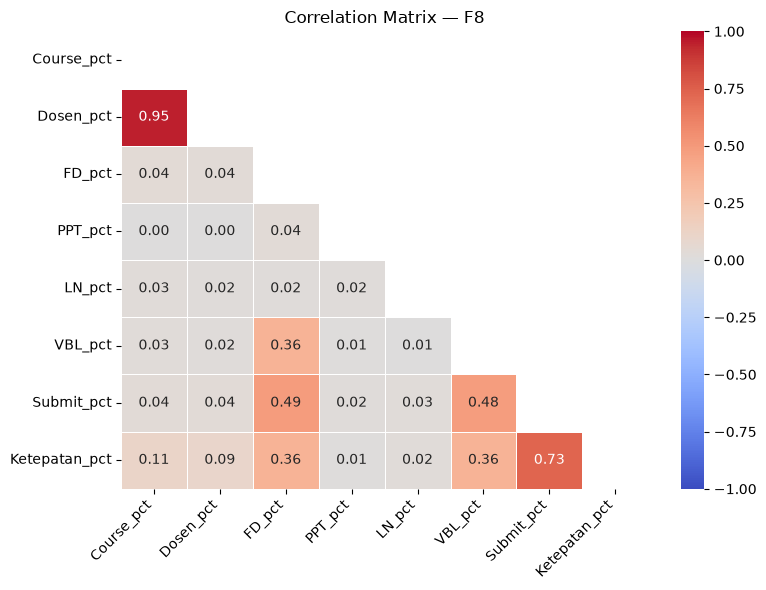

In [30]:
corr_matrix = (
    df[
        CLUSTER_FEATURES
    ]
    .corr(
        method="pearson"
    )
)

plt.figure(
    figsize=(
        max(
            8,
            len(
                CLUSTER_FEATURES
            ),
        ),
        max(
            6,
            len(
                CLUSTER_FEATURES
            )
            * 0.7,
        ),
    )
)

mask = np.triu(
    np.ones_like(
        corr_matrix,
        dtype=bool,
    )
)

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)

plt.title(
    f"Correlation Matrix — {ACTIVE_CASE}"
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.yticks(
    rotation=0,
)

plt.tight_layout()
plt.show()


## 20. Class-Level Business Evaluation

Cluster composition dihitung pada:

`Kode_Periode × Kode Mata kuliah × Kode Kelas`

Metrik:

- dominant cluster share,
- normalized Shannon entropy,
- jumlah cluster dengan share ≥10%,
- filter minimum 20 record untuk ringkasan business utama.


In [31]:
class_cluster_long = (
    df.groupby(
        CLASS_GROUP_COLUMNS
        + [
            "Cluster"
        ],
        dropna=False,
    )
    .size()
    .rename(
        "Jumlah"
    )
    .reset_index()
)

class_cluster_long[
    "Share"
] = (
    class_cluster_long[
        "Jumlah"
    ]
    / class_cluster_long.groupby(
        CLASS_GROUP_COLUMNS
    )[
        "Jumlah"
    ]
    .transform(
        "sum"
    )
)

class_cluster_wide = (
    class_cluster_long
    .pivot_table(
        index=CLASS_GROUP_COLUMNS,
        columns="Cluster",
        values="Share",
        fill_value=0,
    )
    .reset_index()
)

class_business_rows = []

for group_values, group_df in (
    class_cluster_long.groupby(
        CLASS_GROUP_COLUMNS,
        dropna=False,
    )
):
    shares = (
        group_df[
            "Share"
        ]
        .to_numpy(
            dtype=float
        )
    )

    positive_shares = (
        shares[
            shares > 0
        ]
    )

    entropy = -np.sum(
        positive_shares
        * np.log(
            positive_shares
        )
    )

    normalized_entropy = (
        entropy
        / np.log(
            K_FINAL
        )
        if K_FINAL > 1
        else 0.0
    )

    row = {
        column: value
        for column, value in zip(
            CLASS_GROUP_COLUMNS,
            group_values,
        )
    }

    row.update(
        {
            "Jumlah_Record": int(
                group_df[
                    "Jumlah"
                ]
                .sum()
            ),
            "Dominant_Cluster_Share": float(
                shares.max()
            ),
            "Normalized_Entropy": float(
                normalized_entropy
            ),
            "Meaningful_Cluster_Count": int(
                np.sum(
                    shares
                    >= CLASS_MEANINGFUL_SHARE
                )
            ),
        }
    )

    class_business_rows.append(
        row
    )

class_business_metrics = pd.DataFrame(
    class_business_rows
)

class_business_eligible = (
    class_business_metrics[
        class_business_metrics[
            "Jumlah_Record"
        ]
        >= MIN_CLASS_SIZE_FOR_BUSINESS
    ]
    .copy()
)

display(
    class_cluster_wide.head(
        20
    )
    .round(
        4
    )
)

print(
    f"Jumlah class-course-period total: "
    f"{len(class_business_metrics):,}"
)

print(
    f"Eligible (>= {MIN_CLASS_SIZE_FOR_BUSINESS} record): "
    f"{len(class_business_eligible):,}"
)

if not class_business_eligible.empty:
    fraction_multi_profile_classes = (
        class_business_eligible[
            "Meaningful_Cluster_Count"
        ]
        .ge(
            2
        )
        .mean()
    )

    mean_dominant_share = (
        class_business_eligible[
            "Dominant_Cluster_Share"
        ]
        .mean()
    )

    mean_class_entropy = (
        class_business_eligible[
            "Normalized_Entropy"
        ]
        .mean()
    )

    print(
        "Eligible classes dengan >=2 meaningful cluster: "
        f"{fraction_multi_profile_classes * 100:.2f}%"
    )

    print(
        "Mean dominant cluster share: "
        f"{mean_dominant_share * 100:.2f}%"
    )

    print(
        "Mean normalized class entropy: "
        f"{mean_class_entropy:.4f}"
    )

else:
    fraction_multi_profile_classes = (
        np.nan
    )

    mean_dominant_share = (
        np.nan
    )

    mean_class_entropy = (
        np.nan
    )


Cluster,Kode_Periode,Kode Mata kuliah,Kode Kelas,0,1,2,3
0,2011,ISYS6299,JEBA,0.9250,0.000,0.0500,0.0250
1,2011,ISYS6299,JFBA,0.9000,0.000,0.0500,0.0500
2,2011,ISYS6299,JGBA,0.8919,0.000,0.0270,0.0811
3,2012,ISYS6299,JIBA,0.8919,0.000,0.0541,0.0541
4,2012,ISYS6299,JJBA,0.8000,0.000,0.1143,0.0857
5,2012,ISYS6300,DCBA,0.9000,0.050,0.0500,0.0000
6,2012,ISYS6300,JFBA,0.8250,0.025,0.1000,0.0500
7,2012,ISYS6300,JGBA,0.7568,0.000,0.1351,0.1081
8,2012,ISYS6300,JHBA,0.8750,0.000,0.0500,0.0750
9,2012,ISYS6305,JDBA,1.0000,0.000,0.0000,0.0000


Jumlah class-course-period total: 270
Eligible (>= 20 record): 154
Eligible classes dengan >=2 meaningful cluster: 46.10%
Mean dominant cluster share: 84.79%
Mean normalized class entropy: 0.3411


## 21. Optional — Benchmark Seluruh 35 Kombinasi

Default `RUN_ALL_35_BENCHMARK = False`.

Jika diubah menjadi `True`, notebook akan menjalankan:

`5 feature case × 7 preprocessing = 35 kombinasi`

dan menyimpan ringkasan best/fixed K beserta Silhouette, DBI, CH, Inertia, serta cluster
balance.

### Dua mode perbandingan

- `BENCHMARK_K_OVERRIDE = None`: setiap kombinasi memilih K dengan rule yang sama.
- `BENCHMARK_K_OVERRIDE = 3`: seluruh kombinasi dibandingkan pada K=3 yang sama.

Mode fixed-K lebih apple-to-apple bila tujuan eksperimen adalah murni menguji efek
feature selection dan preprocessing pada jumlah cluster yang sama.


In [32]:
def benchmark_one_combination(
    dataframe,
    case_name,
    transform_name,
):
    features = (
        FEATURE_CASES[
            case_name
        ]
    )

    X_case_raw = (
        dataframe[
            features
        ]
        .to_numpy(
            dtype=float
        )
    )

    prep = build_preprocessor(
        transform_name,
        len(
            X_case_raw
        ),
    )

    X_case = prep.fit_transform(
        X_case_raw
    )

    rows = []

    for k in K_CANDIDATES:
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=SEARCH_N_INIT,
            max_iter=MAX_ITER,
        )

        labels = model.fit_predict(
            X_case
        )

        sizes = cluster_size_metrics(
            labels
        )

        rows.append(
            {
                "K": k,
                "Inertia": model.inertia_,
                "Silhouette": silhouette_score(
                    X_case,
                    labels,
                ),
                "DBI": davies_bouldin_score(
                    X_case,
                    labels,
                ),
                "CH": calinski_harabasz_score(
                    X_case,
                    labels,
                ),
                **sizes,
            }
        )

    evaluation = pd.DataFrame(
        rows
    )

    if BENCHMARK_K_OVERRIDE is None:
        selected_k = select_auto_k(
            evaluation,
            AUTO_K_CRITERION,
        )

        k_mode = (
            f"AUTO_{AUTO_K_CRITERION.upper()}"
        )

    else:
        selected_k = int(
            BENCHMARK_K_OVERRIDE
        )

        k_mode = (
            "FIXED"
        )

    selected = (
        evaluation[
            evaluation[
                "K"
            ]
            == selected_k
        ]
        .iloc[
            0
        ]
    )

    return {
        "Feature_Case": case_name,
        "N_Features": len(
            features
        ),
        "Transform": transform_name,
        "Selected_K": selected_k,
        "K_Mode": k_mode,
        "Silhouette": selected[
            "Silhouette"
        ],
        "DBI": selected[
            "DBI"
        ],
        "CH": selected[
            "CH"
        ],
        "Inertia": selected[
            "Inertia"
        ],
        "Smallest_Cluster": selected[
            "Smallest_Cluster"
        ],
        "Largest_Cluster": selected[
            "Largest_Cluster"
        ],
        "Largest_Cluster_Share": selected[
            "Largest_Cluster_Share"
        ],
    }


if RUN_ALL_35_BENCHMARK:
    benchmark_rows = []

    total_combinations = (
        len(
            FEATURE_CASES
        )
        * len(
            TRANSFORM_METHODS
        )
    )

    combination_index = 0

    for case_name in [
        "F12",
        "F11",
        "F9",
        "F8",
        "F6",
    ]:
        for transform_name in TRANSFORM_METHODS:
            combination_index += 1

            print(
                f"[{combination_index}/{total_combinations}] "
                f"{case_name} + {transform_name}"
            )

            try:
                result = benchmark_one_combination(
                    dataframe=df,
                    case_name=case_name,
                    transform_name=transform_name,
                )

                result[
                    "Status"
                ] = (
                    "OK"
                )

                result[
                    "Error"
                ] = (
                    ""
                )

            except Exception as error:
                result = {
                    "Feature_Case": case_name,
                    "N_Features": len(
                        FEATURE_CASES[
                            case_name
                        ]
                    ),
                    "Transform": transform_name,
                    "Selected_K": np.nan,
                    "K_Mode": (
                        "FAILED"
                    ),
                    "Silhouette": np.nan,
                    "DBI": np.nan,
                    "CH": np.nan,
                    "Inertia": np.nan,
                    "Smallest_Cluster": np.nan,
                    "Largest_Cluster": np.nan,
                    "Largest_Cluster_Share": np.nan,
                    "Status": (
                        "ERROR"
                    ),
                    "Error": (
                        f"{type(error).__name__}: "
                        f"{error}"
                    ),
                }

            benchmark_rows.append(
                result
            )

    all_35_benchmark = pd.DataFrame(
        benchmark_rows
    )

    display(
        all_35_benchmark.sort_values(
            "Silhouette",
            ascending=False,
            na_position="last",
        )
        .round(
            5
        )
    )

else:
    all_35_benchmark = (
        pd.DataFrame()
    )

    print(
        "RUN_ALL_35_BENCHMARK=False. "
        "Benchmark seluruh 35 kombinasi dilewati."
    )


RUN_ALL_35_BENCHMARK=False. Benchmark seluruh 35 kombinasi dilewati.


## 22. Ringkasan Eksperimen Aktif

In [33]:
print(
    "=" * 88
)

print(
    "RINGKASAN K-MEANS EXPERIMENT"
)

print(
    "=" * 88
)

print(
    f"Feature case               : "
    f"{ACTIVE_CASE}"
)

print(
    f"Jumlah fitur               : "
    f"{len(CLUSTER_FEATURES)}"
)

print(
    f"Preprocessing              : "
    f"{ACTIVE_TRANSFORM}"
)

print(
    f"K selection                : "
    f"{K_SELECTION_MODE}"
)

print(
    f"K final                    : "
    f"{K_FINAL}"
)

print(
    f"Silhouette                 : "
    f"{sil_score:.5f}"
)

print(
    f"DBI                        : "
    f"{dbi_score:.5f}"
)

print(
    f"CH                         : "
    f"{ch_score:.2f}"
)

print(
    f"Inertia                    : "
    f"{inertia:.2f}"
)

print(
    f"Smallest cluster           : "
    f"{size_final['Smallest_Cluster']:,}"
)

print(
    f"Largest cluster share      : "
    f"{size_final['Largest_Cluster_Share'] * 100:.2f}%"
)

print(
    f"Negative silhouette        : "
    f"{(sample_silhouette < 0).mean() * 100:.2f}%"
)

print(
    f"Seed ARI mean / std        : "
    f"{seed_stability['ARI_vs_Final'].mean():.5f} / "
    f"{seed_stability['ARI_vs_Final'].std():.5f}"
)

print(
    f"Grouped-NIM ARI mean / std : "
    f"{grouped_nim_stability['ARI_vs_Final'].mean():.5f} / "
    f"{grouped_nim_stability['ARI_vs_Final'].std():.5f}"
)

if not class_business_eligible.empty:
    print(
        f"Eligible classes >=2 profile: "
        f"{fraction_multi_profile_classes * 100:.2f}%"
    )

print(
    "=" * 88
)

if ACTIVE_CASE == "F12":
    print(
        "F12 memasukkan avg_LO1/2/3 dan Total_LO sekaligus. "
        "Interpretasikan peningkatan metric dengan memperhatikan "
        "redundansi linear LO."
    )

elif ACTIVE_CASE in {
    "F11",
    "F9",
}:
    print(
        "LO components digunakan dalam clustering. "
        "Total_LO bukan external validation independen."
    )

elif ACTIVE_CASE == "F8":
    print(
        "LO tidak digunakan dalam clustering dan dapat dipakai "
        "sebagai external outcome/profile."
    )

elif ACTIVE_CASE == "F6":
    print(
        "Submit/Ketepatan dan LO tidak digunakan dalam clustering "
        "dan menjadi external profile."
    )

if ACTIVE_TRANSFORM == "STANDARD_L2":
    print(
        "STANDARD_L2 menormalisasi setiap record ke unit norm. "
        "Interpretasinya berbeda dari per-feature scaling biasa."
    )

if ACTIVE_TRANSFORM == "ROBUST_MINMAX":
    print(
        "ROBUST_MINMAX berpotensi redundant dengan MINMAX. "
        "Bandingkan assignment/ARI sebelum menganggap keduanya "
        "sebagai metode yang benar-benar berbeda."
    )


RINGKASAN K-MEANS EXPERIMENT
Feature case               : F8
Jumlah fitur               : 8
Preprocessing              : ROBUST
K selection                : MANUAL_OVERRIDE
K final                    : 4
Silhouette                 : 0.84195
DBI                        : 0.34072
CH                         : 36864.56
Inertia                    : 42983.13
Smallest cluster           : 60
Largest cluster share      : 84.19%
Negative silhouette        : 0.00%
Seed ARI mean / std        : 1.00000 / 0.00000
Grouped-NIM ARI mean / std : 1.00000 / 0.00000
Eligible classes >=2 profile: 46.10%
LO tidak digunakan dalam clustering dan dapat dipakai sebagai external outcome/profile.


## 23. Export Hasil ke Excel dan CSV

In [34]:
OUTPUT_DIR = Path(
    "output"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

safe_transform_name = (
    ACTIVE_TRANSFORM
    .replace(
        " ",
        "_",
    )
)

OUTPUT_XLSX = (
    OUTPUT_DIR
    / (
        f"Hasil_KMeans_{ACTIVE_CASE}_"
        f"{safe_transform_name}_K{K_FINAL}.xlsx"
    )
)

OUTPUT_CSV = (
    OUTPUT_DIR
    / (
        f"Hasil_KMeans_{ACTIVE_CASE}_"
        f"{safe_transform_name}_K{K_FINAL}.csv"
    )
)

export_columns = (
    ID_COLUMNS
    + ALL_MODEL_FEATURES
    + [
        "Cluster"
    ]
)

df_export = (
    df[
        export_columns
    ]
    .copy()
)

with pd.ExcelWriter(
    OUTPUT_XLSX,
    engine="openpyxl",
) as writer:
    df_export.to_excel(
        writer,
        sheet_name="Hasil_Cluster",
        index=False,
    )

    final_metrics.to_excel(
        writer,
        sheet_name="Metrik_Final",
        index=False,
    )

    k_evaluation.to_excel(
        writer,
        sheet_name="Evaluasi_K",
        index=False,
    )

    cluster_distribution.to_excel(
        writer,
        sheet_name="Distribusi_Cluster",
    )

    empirical_profile_mean.to_excel(
        writer,
        sheet_name="Empirical_Mean",
    )

    empirical_profile_median.to_excel(
        writer,
        sheet_name="Empirical_Median",
    )

    centers_transformed_df.to_excel(
        writer,
        sheet_name="Centroid_Transformed",
    )

    if not centroid_original_df.empty:
        centroid_original_df.to_excel(
            writer,
            sheet_name="Centroid_Original",
        )

    preprocess_diagnostic.to_excel(
        writer,
        sheet_name="Preprocess_Diagnostic",
        index=False,
    )

    silhouette_by_cluster.to_excel(
        writer,
        sheet_name="Silhouette_Cluster",
    )

    feature_separation.to_excel(
        writer,
        sheet_name="Feature_Separation",
        index=False,
    )

    pca_loadings.to_excel(
        writer,
        sheet_name="PCA_Loadings",
    )

    seed_stability.to_excel(
        writer,
        sheet_name="Stability_Seed",
        index=False,
    )

    grouped_nim_stability.to_excel(
        writer,
        sheet_name="Stability_NIM",
        index=False,
    )

    if not external_profile_mean.empty:
        external_profile_mean.to_excel(
            writer,
            sheet_name="External_Mean",
        )

        external_profile_median.to_excel(
            writer,
            sheet_name="External_Median",
        )

        external_profile_std.to_excel(
            writer,
            sheet_name="External_Std",
        )

    class_cluster_long.to_excel(
        writer,
        sheet_name="Class_Cluster_Long",
        index=False,
    )

    class_cluster_wide.to_excel(
        writer,
        sheet_name="Class_Cluster_Share",
        index=False,
    )

    class_business_metrics.to_excel(
        writer,
        sheet_name="Class_Business",
        index=False,
    )

    corr_matrix.to_excel(
        writer,
        sheet_name="Correlation",
    )

    if not all_35_benchmark.empty:
        all_35_benchmark.to_excel(
            writer,
            sheet_name="Benchmark_35",
            index=False,
        )

df_export.to_csv(
    OUTPUT_CSV,
    index=False,
)

print(
    f"Excel output: "
    f"{OUTPUT_XLSX.resolve()}"
)

print(
    f"CSV output  : "
    f"{OUTPUT_CSV.resolve()}"
)


Excel output: D:\Binus_Adhit_V1\Binus-Project\Folder-Clustering\Modeling\KMeans-Model\Robust-Scaler\output\Hasil_KMeans_F8_ROBUST_K4.xlsx
CSV output  : D:\Binus_Adhit_V1\Binus-Project\Folder-Clustering\Modeling\KMeans-Model\Robust-Scaler\output\Hasil_KMeans_F8_ROBUST_K4.csv


## 24. Panduan Eksperimen 35 Kombinasi

Untuk eksperimen manual, jalankan notebook berulang dengan mengganti:

```python
ACTIVE_CASE = "F12"
ACTIVE_TRANSFORM = "STANDARD"
```

Contoh lain:

```python
ACTIVE_CASE = "F9"
ACTIVE_TRANSFORM = "MINMAX_POWER"
```

### Urutan feature case

`F12`, `F11`, `F9`, `F8`, `F6`

### Urutan preprocessing

`STANDARD`, `MINMAX`, `POWER`, `QUANTILE`, `ROBUST_MINMAX`,
`MINMAX_POWER`, `STANDARD_L2`

### Cara membandingkan hasil

Jangan memilih kombinasi final hanya karena Silhouette paling tinggi. Untuk project ini
perhatikan bersama-sama:

- Silhouette,
- DBI,
- CH,
- cluster balance,
- per-cluster silhouette,
- feature separation,
- seed stability,
- grouped-NIM stability,
- external outcome/profile,
- class-level composition.

Jika tujuan utama adalah membandingkan **efek preprocessing** secara murni, sebaiknya
gunakan `BENCHMARK_K_OVERRIDE` yang sama. Jika tujuan adalah mencari konfigurasi terbaik
masing-masing kombinasi, gunakan auto-K yang sama untuk seluruh kombinasi.
